# Clasificación de 76 especies de aves con CNN - Proyecto final Topicos Avanzados en analitica

**Autores:** Daniel Rodríguez Aponte - Angie Vanessa Muñoz Bonilla - David Steven Rodriguez Castro - Angélica Lorena Rodriguez Gamboa.

**Profesor:** Omar Cuervo Fernandez.

**Pontificia Universidad Javeriana**

## 1. Objetivo y alcance

### Objetivo
Construir, entrenar, optimizar y evaluar un modelo de **clasificación multiclase de imágenes** capaz de reconocer  76 especies de aves listadas, a partir de imágenes de la base iNaturalist ya almacenadas localmente.

### Alcance
| Incluido |
|---|
| Validación de nombres CSV ↔ carpetas, auditoría de imágenes y detección de fugas de información |
| CNN pequeña desde cero (baseline) |
| Transfer learning con EfficientNet-B0, ConvNeXt-Tiny, ResNet50 y EfficientNetV2-S |
| Optimización bayesiana (Optuna + TPE) con pruning, early stopping y AMP |
| Evaluación final única sobre `test`, comparación contra `acc_baseline`, Grad-CAM, exportación (`.pth`, TorchScript, ONNX)|

### Flujo general

CSV (76 especies) ─► emparejamiento con carpetas ─► auditoría (corruptos, conteos) ─► control de fugas
      ─► EDA + augmentation ─► CNN desde cero  |  modelos preentrenados ─► mejor configuración por Macro F1 de validación ─► entrenamiento final + early stopping
      ─► evaluación sobre test ─► comparación con baseline ─► Grad-CAM ─► exportación

## 2. Consideraciones técnicas y decisiones de diseño

### 2.1 Por qué transferencia de aprendizaje
Con 76 clases y, previsiblemente, decenas de imágenes por especie, entrenar una CNN profunda desde cero sobreajusta con facilidad. Los modelos preentrenados en ImageNet ya saben detectar bordes, texturas, patrones de plumaje y formas; solo hay que adaptar esas representaciones. Por eso es la estrategia principal. La CNN desde cero se mantiene como **linea base para comparar**; la decisión final la toman las métricas de validación.

### 2.2 Presupuesto de memoria (8 GB de VRAM)

La siguiente tabla muestra el peso esperado de cada uno de los modelos preentrenados para no exceder el presupuesto de memoria

| Modelo | Parámetros | 224 px, batch 32 | 256 px, batch 32 |
|---|---|---|---|
| EfficientNet-B0 | 5.3 M | ~3–4 GB | ~4–5 GB |
| ResNet50 | 25.6 M | ~4–5 GB | ~5–6.5 GB |
| ConvNeXt-Tiny | 28.6 M | ~4.5–5.5 GB | ~6–7.5 GB |
| EfficientNetV2-S (opcional) | 21.5 M | ~6–7.5 GB | **riesgo de OOM** → el cuaderno limita su batch a 16 |

### 2.3 Caché de imágenes redimensionadas
Las fotos de iNaturalist pueden tener resoluciones altas; decodificar JPEG grandes en CPU suele ser el cuello de botella, no la GPU. El cuaderno puede crear una **copia redimensionada** (lado corto = 320 px) en `outputs_aves76/cache_320/`, **sin tocar los originales**. Acelera cada época entre 2× y 5× cuando las imágenes originales son grandes.

### 2.4 Protocolo anti-fuga (data leakage)
`train` → ajustar pesos · `val` → early stopping, pruning, Optuna y elección del modelo · `test` → **una sola evaluación al final**. Además, se buscan duplicados exactos (MD5) y casi duplicados (pHash) entre particiones.

### 2.6 Estimación orientativa del tiempo

| Imágenes en train (76 clases) | Época aprox. | Trial (10 épocas) | 25 trials (con pruning) | Entrenamiento final (30 épocas) |
|---|---|---|---|---|
| ~3 000 (≈40/clase) | 5–15 s | 1–3 min | 0.5–1.5 h | 5–10 min |
| ~8 000 (≈100/clase) | 15–35 s | 3–6 min | 1–2.5 h | 10–20 min |
| ~15 000 (≈200/clase) | 30–70 s | 5–12 min | 2–4.5 h | 20–40 min |

## 3. Instalación e importación de dependencias

### 3.1 Dependencias
| Paquete | Uso | ¿Obligatorio? |
|---|---|---|
| `torch`, `torchvision` (≥ 2.3 / ≥ 0.18) con CUDA | Modelos, entrenamiento, AMP, pesos ImageNet | Sí |
| `optuna` (≥ 3.5) | Optimización bayesiana TPE, pruning, SQLite | Sí |
| `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `pillow`, `tqdm` | Datos, métricas, gráficos | Sí |
| `imagehash` | Casi duplicados con perceptual hash | Opcional |
| `onnx`, `onnxruntime` | Exportación y verificación ONNX | Opcional |
| `ipywidgets` | Barras de progreso de `tqdm` en VS Code | Recomendado |

In [1]:
# Descomenta para instalar desde el cuaderno (luego reinicia el kernel).
# %pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124
# %pip install optuna numpy pandas scikit-learn matplotlib pillow tqdm ipywidgets imagehash onnx onnxruntime

In [2]:
import os
import sys
import gc
import re
import json
import math
import time
import copy
import random
import shutil
import hashlib
import difflib
import platform
import warnings
import unicodedata
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, UnidentifiedImageError
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, WeightedRandomSampler
import torchvision
from torchvision import models

import sklearn
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    f1_score, confusion_matrix, classification_report,
)

import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

try:
    import imagehash
    IMAGEHASH_AVAILABLE = True
except ImportError:
    IMAGEHASH_AVAILABLE = False
    print("⚠️  'imagehash' no está instalado: se omitirá la búsqueda de casi duplicados (pHash). "
          "Instala con: pip install imagehash")

warnings.filterwarnings("ignore", category=UserWarning, module="torch.optim.lr_scheduler")
warnings.filterwarnings("ignore", message=".*y_pred contains classes not in y_true.*")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

_tv = tuple(int(x) for x in re.findall(r"\d+", torch.__version__)[:2])
if _tv < (2, 3):
    print(f"⚠️  PyTorch {torch.__version__} detectado. Se recomienda >= 2.3 para la API torch.amp usada aquí.")
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | torchvision {torchvision.__version__} | Optuna {optuna.__version__}")

Python 3.11.9 | PyTorch 2.6.0+cu124 | torchvision 0.21.0+cu124 | Optuna 5.0.0


### 3.2 Módulo auxiliar `aves_data.py` (necesario en Windows)

**Qué:** escribimos en disco un pequeño módulo con el `Dataset`, las transformaciones y la semilla de los workers.  
**Por qué:** con `num_workers > 0`, Windows lanza procesos nuevos que deben *importar* estas clases; si vivieran solo en el cuaderno fallarían.  
**Qué contiene:**
- `BirdDataset`: lee la imagen, corrige la orientación EXIF, convierte a RGB y aplica la transformación.
- `build_train_transform(image_size, aug_level)` y `build_eval_transform(image_size)`.
- `seed_worker`: semilla reproducible por worker.

Los niveles de *augmentation* (`light`, `medium`, `strong`) se explican en la sección 11. La celda sobrescribe el archivo cada vez que se ejecuta, por lo que cualquier cambio aquí se propaga.

In [3]:
%%writefile aves_data.py
"""Utilidades de datos importables por los workers del DataLoader (requisito en Windows)."""
import random

import numpy as np
import torch
from PIL import Image, ImageOps
from torch.utils.data import Dataset
from torchvision import transforms as T

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Parámetros por nivel de augmentation. Se evitan transformaciones extremas:
# el matiz (hue) casi no se altera porque el color del plumaje es diagnóstico,
# no hay flips verticales (un ave boca abajo no es realista) y la rotación es moderada.
AUG_LEVELS = {
    "light":  dict(scale=(0.60, 1.0), rot=10, bright=0.15, contrast=0.15, sat=0.10, hue=0.00, erase_p=0.10, randaug=False),
    "medium": dict(scale=(0.45, 1.0), rot=15, bright=0.20, contrast=0.20, sat=0.15, hue=0.02, erase_p=0.20, randaug=False),
    "strong": dict(scale=(0.35, 1.0), rot=20, bright=0.25, contrast=0.25, sat=0.20, hue=0.03, erase_p=0.25, randaug=True),
}


def build_train_transform(image_size, aug_level="medium", mean=IMAGENET_MEAN, std=IMAGENET_STD):
    if aug_level not in AUG_LEVELS:
        raise ValueError(f"aug_level debe ser uno de {list(AUG_LEVELS)}; recibido: {aug_level}")
    p = AUG_LEVELS[aug_level]
    ops = [
        T.RandomResizedCrop(image_size, scale=p["scale"], ratio=(3 / 4, 4 / 3), antialias=True),
        T.RandomHorizontalFlip(p=0.5),
        T.RandomApply([T.RandomRotation(p["rot"])], p=0.5),
        T.RandomApply([T.ColorJitter(p["bright"], p["contrast"], p["sat"], p["hue"])], p=0.7),
    ]
    if p["randaug"]:
        # RandAugment de magnitud moderada (escala 0-30). Solo en el nivel 'strong'.
        ops.append(T.RandAugment(num_ops=2, magnitude=7))
    ops += [
        T.ToTensor(),
        T.Normalize(mean, std),
        T.RandomErasing(p=p["erase_p"], scale=(0.02, 0.12), ratio=(0.3, 3.3), value=0),
    ]
    return T.Compose(ops)


def build_eval_transform(image_size, mean=IMAGENET_MEAN, std=IMAGENET_STD, resize_ratio=1.14):
    """Transformación determinista: redimensiona el lado corto y recorta el centro."""
    return T.Compose([
        T.Resize(int(round(image_size * resize_ratio)), antialias=True),
        T.CenterCrop(image_size),
        T.ToTensor(),
        T.Normalize(mean, std),
    ])


def load_rgb(path):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img)
        return img.convert("RGB")


class BirdDataset(Dataset):
    """Dataset en memoria: solo guarda rutas y etiquetas; las imágenes se leen bajo demanda."""

    def __init__(self, paths, labels, transform=None):
        if len(paths) != len(labels):
            raise ValueError("paths y labels deben tener la misma longitud")
        self.paths = [str(p) for p in paths]
        self.labels = [int(l) for l in labels]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        try:
            img = load_rgb(path)
        except Exception as exc:  # imagen corrupta no detectada en la auditoría
            raise RuntimeError(f"No se pudo leer la imagen: {path} ({exc})") from exc
        if self.transform is not None:
            img = self.transform(img)
        return img, self.labels[idx]


def seed_worker(worker_id):
    """Semilla determinista por worker (recomendación oficial de PyTorch)."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

Overwriting aves_data.py


In [4]:
import importlib
import aves_data
importlib.reload(aves_data)
from aves_data import (BirdDataset, build_train_transform, build_eval_transform, seed_worker,
                       load_rgb, IMAGENET_MEAN, IMAGENET_STD, AUG_LEVELS)
print("Módulo aves_data cargado desde:", Path(aves_data.__file__).resolve())

Módulo aves_data cargado desde: C:\Users\User\Desktop\CNN - Aves\aves_data.py


## 4. Configuración general y rutas

| Variable | Qué controla | Más alto → | Más bajo → |
|---|---|---|---|
| `QUICK_MODE` | Prueba rápida del pipeline (pocos batches, épocas y trials) | — | — |
| `N_TRIALS` / `N_TRIALS_CNN` | Trials de Optuna (preentrenados / CNN desde cero) | Mejor búsqueda, más tiempo | Más rápido, búsqueda más pobre |
| `MAX_EPOCHS_TRIAL` | Épocas por trial | Estimación más fiel | Trials baratos y ruidosos |
| `FINAL_EPOCHS` | Épocas máximas del modelo final | Mejor ajuste (early stopping corta si no mejora) | Menos tiempo |
| `IMAGE_SIZE` / `IMAGE_SIZE_CHOICES` | Resolución por defecto / candidatas en Optuna | Más detalle del plumaje, más VRAM | Más rápido |
| `BATCH_SIZE` / `BATCH_SIZE_CHOICES` | Batch por defecto / candidatos | Gradiente más estable, más VRAM | Menos VRAM, más ruido |
| `GRAD_ACCUM_STEPS` | Acumulación de gradientes | Batch efectivo mayor sin más VRAM | — |
| `NUM_WORKERS` | Procesos de carga de imágenes | Más rápido (si la CPU lo permite) | Más estable en Windows |
| `CANDIDATE_ARCHS` / `INCLUDE_EFFNETV2S` | Arquitecturas comparadas | Búsqueda más amplia | Más rápida |
| `IMBALANCE_STRATEGY` | `none`, `sampler`, `class_weights`, `focal` | — | — |
| `OPTIMIZE_IMBALANCE` | Si Optuna elige la estrategia de desbalance | Más exploración | Menos trials desperdiciados |
| `ON_MISSING_SPECIES` | `"stop"` o `"continue"` si falta alguna especie | — | — |
| `LEAKAGE_ACTION` | `"report"` o `"exclude_eval"` para duplicados exactos | — | — |
| `USE_RESIZED_CACHE` | Copia redimensionada de las imágenes | Mucho más rápido | Usa los originales |
| `MANUAL_FOLDER_OVERRIDES` | Emparejamientos manuales especie → carpeta | — | — |

In [5]:
# ============================== RUTAS ==============================
PROJECT_ROOT = Path.cwd()                       # carpeta donde está este cuaderno
DATASET_ROOT = PROJECT_ROOT / "dataset_seg"     # contiene train/ val/ test/
CSV_PATH = PROJECT_ROOT / "especies_top76.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs_aves76"
SPLITS = ("train", "val", "test")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}

# ============================== MODO ===============================
QUICK_MODE = False            # True: prueba rápida del pipeline | False: entrenamiento completo
RANDOM_SEED = 42
DETERMINISTIC = True        # True: más reproducible pero más lento (ver sección 5)

# ============================ HARDWARE =============================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 4              # Windows: 2-4 recomendado. Si hay errores o bloqueos -> 2 -> 0
USE_AMP = True               # mixed precision (solo tiene efecto en CUDA)
GRAD_ACCUM_STEPS = 1         # batch efectivo = BATCH_SIZE * GRAD_ACCUM_STEPS
GRAD_CLIP_NORM = 1.0         # recorte de la norma del gradiente (None para desactivar)
OOM_RETRY = True             # ante OutOfMemory: reintenta con batch/2 y acumulación x2

# ============================== DATOS ==============================
IMAGE_SIZE = 224
BATCH_SIZE = 32
USE_RESIZED_CACHE = True     # copia redimensionada en OUTPUT_DIR/cache_<lado>; NO toca originales
CACHE_SHORT_SIDE = 320       # suficiente para 256 px (256 * 1.14 = 292 < 320)
FULL_IMAGE_CHECK = True      # decodifica cada imagen completa en la auditoría (más lento, más seguro)
ON_MISSING_SPECIES = "continue"   # "stop" | "continue" (solo clases válidas en las 3 particiones)
MATCH_BY_COMMON_NAME = True  # intenta emparejar por nombre común si falla el científico (se marca en el reporte)
MANUAL_FOLDER_OVERRIDES = {  # especie (CSV) -> nombre exacto de carpeta. Ej.: {"Ardea ibis": "Bubulcus ibis"}
}
LEAKAGE_ACTION = "exclude_eval"   # "report" | "exclude_eval": quita de val/test los duplicados exactos de train
CHECK_PHASH = True           # casi duplicados (requiere imagehash)
PHASH_MAX_DISTANCE = 4       # distancia de Hamming (0-64). <=4 suele indicar la misma foto recortada/recomprimida

# ======================= DESBALANCE DE CLASES ======================
IMBALANCE_STRATEGY = "none"  # "none" | "sampler" | "class_weights" | "focal"
OPTIMIZE_IMBALANCE = True    # si True, Optuna elige entre las estrategias
CLASS_WEIGHT_POWER = 0.5     # peso = (1/frecuencia)^potencia -> 0.5 = raíz inversa (moderado)
FOCAL_GAMMA = 2.0

# ============================= MODELOS =============================
CANDIDATE_ARCHS = ["efficientnet_b0", "convnext_tiny", "resnet50"]
INCLUDE_EFFNETV2S = False    # True añade EfficientNetV2-S (batch limitado a 16)
IMAGE_SIZE_CHOICES = [224, 256]
BATCH_SIZE_CHOICES = [8, 16, 32]
SCRATCH_IMAGE_SIZE_CHOICES = [160, 224]

# ============================== OPTUNA =============================
N_TRIALS = 25                # modelos preentrenados
N_TRIALS_CNN = 8             # CNN desde cero (baseline)
MAX_EPOCHS_TRIAL = 10
PHASE1_EPOCHS_TRIAL = 2      # épocas con backbone congelado dentro de cada trial
PATIENCE_TRIAL = 3
OPTUNA_TIMEOUT_HOURS = None  # límite de tiempo global por estudio (None = sin límite)

# ======================== ENTRENAMIENTO FINAL ======================
FINAL_EPOCHS = 30
PHASE1_EPOCHS_FINAL = 3
PATIENCE_FINAL = 7
MIN_DELTA = 1e-3             # mejora mínima de Macro F1 para reiniciar la paciencia
RESUME_FINAL = True          # reanuda desde el último checkpoint si existe y la configuración coincide

# ============================ QUICK MODE ===========================
MAX_BATCHES = None           # None = todos los batches
if QUICK_MODE:
    N_TRIALS, N_TRIALS_CNN = 3, 2
    MAX_EPOCHS_TRIAL, PHASE1_EPOCHS_TRIAL, PATIENCE_TRIAL = 2, 1, 1
    FINAL_EPOCHS, PHASE1_EPOCHS_FINAL, PATIENCE_FINAL = 3, 1, 2
    MAX_BATCHES = 5
    CANDIDATE_ARCHS = ["efficientnet_b0"]
    IMAGE_SIZE_CHOICES = [224]
    SCRATCH_IMAGE_SIZE_CHOICES = [160]

if INCLUDE_EFFNETV2S and "efficientnet_v2_s" not in CANDIDATE_ARCHS:
    CANDIDATE_ARCHS = CANDIDATE_ARCHS + ["efficientnet_v2_s"]

RUN_TAG = "quick" if QUICK_MODE else "full"
FIG_DIR = OUTPUT_DIR / "figuras"
CKPT_DIR = OUTPUT_DIR / "checkpoints"
EXPORT_DIR = OUTPUT_DIR / "modelo_exportado"
CACHE_DIR = OUTPUT_DIR / f"cache_{CACHE_SHORT_SIDE}"
for d in (OUTPUT_DIR, FIG_DIR, CKPT_DIR, EXPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)
OPTUNA_STORAGE = f"sqlite:///{(OUTPUT_DIR / 'optuna_aves76.db').as_posix()}"

# ===================== VERIFICACIONES DE RUTAS =====================
if not CSV_PATH.is_file():
    raise FileNotFoundError(
        f"No se encontró el CSV en: {CSV_PATH}\n"
        "→ Copia 'especies_top76.csv' junto al cuaderno o ajusta CSV_PATH.")
if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta del dataset: {DATASET_ROOT}\n"
        "→ Ajusta DATASET_ROOT (por ejemplo Path(r'D:\\datos\\dataset_seg')).")
missing_splits = [s for s in SPLITS if not (DATASET_ROOT / s).is_dir()]
if missing_splits:
    raise FileNotFoundError(f"Faltan particiones dentro de {DATASET_ROOT}: {missing_splits}")

if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"✅ GPU: {props.name} | VRAM: {props.total_memory / 1024**3:.1f} GB | CUDA {torch.version.cuda}")
else:
    USE_AMP = False
    print("⚠️  CUDA NO disponible: se entrenará en CPU (muy lento).\n"
          "   Revisa 'nvidia-smi' y reinstala PyTorch con CUDA (sección 3). Se recomienda QUICK_MODE=True.")

if platform.system() == "Windows" and NUM_WORKERS > 6:
    print("ℹ️  NUM_WORKERS alto en Windows: si el kernel se bloquea, redúcelo a 2-4.")

print(f"Modo: {RUN_TAG.upper()} | trials: {N_TRIALS} (+{N_TRIALS_CNN} CNN) | épocas/trial: {MAX_EPOCHS_TRIAL} | "
      f"épocas finales: {FINAL_EPOCHS} | arquitecturas: {CANDIDATE_ARCHS}")
print("Salidas en:", OUTPUT_DIR)

✅ GPU: NVIDIA GeForce RTX 4060 Ti | VRAM: 8.0 GB | CUDA 12.4
Modo: FULL | trials: 25 (+8 CNN) | épocas/trial: 10 | épocas finales: 30 | arquitecturas: ['efficientnet_b0', 'convnext_tiny', 'resnet50']
Salidas en: c:\Users\User\Desktop\CNN - Aves\outputs_aves76


## 5. Reproducibilidad

**Qué se hace:** fijar semillas de Python, NumPy y PyTorch (CPU y CUDA), sembrar cada worker del `DataLoader` y registrar las versiones de las librerías y la configuración.

**Equilibrio reproducibilidad ↔ rendimiento en CUDA:**
- `cudnn.benchmark = True` prueba varios algoritmos de convolución y elige el más rápido para cada tamaño de tensor → **más velocidad**, pero la elección puede variar entre ejecuciones.
- `cudnn.deterministic = True` + `torch.use_deterministic_algorithms(True)` fuerza algoritmos deterministas → resultados repetibles, normalmente **10–30 % más lento**, y algunas operaciones solo tienen versión no determinista (se emite un aviso).
- Con AMP, las sumas en FP16 y el orden de las operaciones atómicas en GPU pueden producir diferencias mínimas incluso con semillas fijas.

Por defecto `DETERMINISTIC = True`: Para un experimento final que deba repetirse exactamente.

In [6]:
def seed_everything(seed: int, deterministic: bool = False) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic
    if deterministic:
        os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
        torch.use_deterministic_algorithms(True, warn_only=True)
    else:
        torch.use_deterministic_algorithms(False)
    # TF32 en Ampere/Ada: más rápido en matmuls FP32 con pérdida de precisión despreciable
    torch.backends.cuda.matmul.allow_tf32 = not deterministic
    torch.backends.cudnn.allow_tf32 = not deterministic


def make_generator(seed: int) -> torch.Generator:
    g = torch.Generator()
    g.manual_seed(seed)
    return g


seed_everything(RANDOM_SEED, DETERMINISTIC)


def library_versions() -> dict:
    info = {
        "python": sys.version.split()[0], "platform": platform.platform(),
        "torch": torch.__version__, "torchvision": torchvision.__version__,
        "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
        "optuna": optuna.__version__, "numpy": np.__version__, "pandas": pd.__version__,
        "sklearn": sklearn.__version__, "PIL": Image.__version__, "matplotlib": matplotlib.__version__,
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    }
    if IMAGEHASH_AVAILABLE:
        info["imagehash"] = getattr(imagehash, "__version__", "desconocida")
    return info


def config_snapshot() -> dict:
    keys = ["DATASET_ROOT", "CSV_PATH", "QUICK_MODE", "RANDOM_SEED", "DETERMINISTIC", "DEVICE", "NUM_WORKERS",
            "USE_AMP", "GRAD_ACCUM_STEPS", "GRAD_CLIP_NORM", "IMAGE_SIZE", "BATCH_SIZE", "USE_RESIZED_CACHE",
            "CACHE_SHORT_SIDE", "ON_MISSING_SPECIES", "LEAKAGE_ACTION", "PHASH_MAX_DISTANCE",
            "IMBALANCE_STRATEGY", "OPTIMIZE_IMBALANCE", "CLASS_WEIGHT_POWER", "FOCAL_GAMMA", "CANDIDATE_ARCHS",
            "IMAGE_SIZE_CHOICES", "BATCH_SIZE_CHOICES", "N_TRIALS", "N_TRIALS_CNN", "MAX_EPOCHS_TRIAL",
            "PHASE1_EPOCHS_TRIAL", "PATIENCE_TRIAL", "FINAL_EPOCHS", "PHASE1_EPOCHS_FINAL", "PATIENCE_FINAL",
            "MIN_DELTA", "MAX_BATCHES"]
    g = globals()
    return {k: (str(g[k]) if isinstance(g[k], (Path, torch.device)) else g[k]) for k in keys}


VERSIONS = library_versions()
with open(OUTPUT_DIR / f"config_{RUN_TAG}.json", "w", encoding="utf-8") as f:
    json.dump({"versions": VERSIONS, "config": config_snapshot()}, f, indent=2, ensure_ascii=False, default=str)
pd.Series(VERSIONS, name="versión").to_frame()

,versión
python,3.11.9
platform,Windows-10-10.0.26200-SP0
torch,2.6.0+cu124
torchvision,0.21.0+cu124
cuda,12.4
cudnn,90100
optuna,5.0.0
numpy,2.3.5
pandas,2.3.3
sklearn,1.8.0


## 6. Lectura y validación del CSV


**Qué:** leer `especies_top76.csv` preservando tildes (`ñ`, `á`, `í`…), limpiar espacios, validar columnas y tipos, detectar duplicados y completar los nombres comunes vacíos.

**Decisiones:**
- Se intenta primero `utf-8-sig` (UTF-8 con o sin BOM, típico de Excel) y, si falla, `cp1252`/`latin-1`.
- La columna `especie` es la **lista oficial de clases**.
- Si `nombre_comun` está vacío (por ejemplo, *Grallaria alticola*), se usa el nombre científico como etiqueta visible y se avisa.
- `display_name` = "Nombre común (*Nombre científico*)" se usa en todos los gráficos.

**Resultado esperado:** 76 especies únicas, sin duplicados, con `acc_baseline` en [0, 1] y `n_test` entero.

In [7]:
def read_species_csv(path: Path) -> pd.DataFrame:
    last_err = None
    for enc in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, encoding=enc, dtype=str, keep_default_na=False)
            print(f"CSV leído con codificación '{enc}'")
            return df
        except UnicodeDecodeError as e:
            last_err = e
    raise ValueError(f"No se pudo decodificar {path}: {last_err}")


species_df = read_species_csv(CSV_PATH)
species_df.columns = [c.strip().lower() for c in species_df.columns]
required_cols = {"especie", "nombre_comun", "acc_baseline", "n_test"}
missing_cols = required_cols - set(species_df.columns)
if missing_cols:
    raise ValueError(f"Faltan columnas en el CSV: {missing_cols}. Columnas encontradas: {list(species_df.columns)}")

for col in ("especie", "nombre_comun"):
    # NFC unifica tildes compuestas/precompuestas; strip y espacios internos múltiples
    species_df[col] = (species_df[col].astype(str)
                       .map(lambda s: unicodedata.normalize("NFC", s))
                       .str.strip().str.replace(r"\s+", " ", regex=True))

species_df = species_df[species_df["especie"] != ""].copy()
species_df["acc_baseline"] = pd.to_numeric(species_df["acc_baseline"], errors="coerce")
species_df["n_test"] = pd.to_numeric(species_df["n_test"], errors="coerce").astype("Int64")

dups = species_df[species_df["especie"].duplicated(keep=False)]
if len(dups):
    print("⚠️  Especies duplicadas en el CSV (se conserva la primera aparición):")
    display(dups)
    species_df = species_df.drop_duplicates("especie", keep="first")

empty_common = species_df["nombre_comun"] == ""
if empty_common.any():
    print(f"ℹ️  {empty_common.sum()} especie(s) sin nombre común; se usará el nombre científico como etiqueta visible:")
    for s in species_df.loc[empty_common, "especie"]:
        print("   -", s)
species_df["nombre_visible"] = np.where(empty_common, species_df["especie"], species_df["nombre_comun"])
species_df["display_name"] = np.where(
    empty_common, species_df["especie"], species_df["nombre_comun"] + " (" + species_df["especie"] + ")")

bad_baseline = species_df["acc_baseline"].isna() | ~species_df["acc_baseline"].between(0, 1)
if bad_baseline.any():
    print("⚠️  Valores de acc_baseline no válidos (se tratarán como NaN):")
    display(species_df.loc[bad_baseline, ["especie", "acc_baseline"]])

print(f"Especies en el CSV: {len(species_df)}")
if len(species_df) != 76:
    print(f"⚠️  Se esperaban 76 especies y hay {len(species_df)}. Revisa el archivo.")
species_df = species_df.reset_index(drop=True)
display(species_df.head(10))
print(species_df[["acc_baseline", "n_test"]].describe().T)

CSV leído con codificación 'utf-8-sig'
ℹ️  1 especie(s) sin nombre común; se usará el nombre científico como etiqueta visible:
   - Grallaria alticola
Especies en el CSV: 76


,especie,nombre_comun,acc_baseline,n_test,nombre_visible,display_name
0,Saucerottia cyanifrons,Amazilia Capiazul,0.50,8,Amazilia Capiazul,Amazilia Capiazul (Saucerottia cyanifrons)
1,Streptoprocne zonaris,Vencejo Collar Blanco,0.38,8,Vencejo Collar Blanco,Vencejo Collar Blanco (Streptoprocne zonaris)
2,Anisognathus somptuosus,Tángara primavera,0.38,8,Tángara primavera,Tángara primavera (Anisognathus somptuosus)
3,Eudocimus ruber,Corocoro rojo,0.38,8,Corocoro rojo,Corocoro rojo (Eudocimus ruber)
4,Grallaria ruficapilla,Comprapán,0.38,8,Comprapán,Comprapán (Grallaria ruficapilla)
5,Plegadis falcinellus,Ibis cara oscura,0.25,8,Ibis cara oscura,Ibis cara oscura (Plegadis falcinellus)
6,Ramphocelus dimidiatus,Sangretoro encendido,0.25,8,Sangretoro encendido,Sangretoro encendido (Ramphocelus dimidiatus)
7,Iridosornis rufivertex,Musguerito Paramuno,0.25,8,Musguerito Paramuno,Musguerito Paramuno (Iridosornis rufivertex)
8,Aramides cajaneus,Chiricote,0.25,8,Chiricote,Chiricote (Aramides cajaneus)
9,Anthracothorax nigricollis,Mango Gorginegro,0.25,8,Mango Gorginegro,Mango Gorginegro (Anthracothorax nigricollis)


             count      mean       std   min   25%   50%   75%  max
acc_baseline  76.0  0.149211   0.07761  0.12  0.12  0.12  0.12  0.5
n_test        76.0  7.986842  0.114708   7.0   8.0   8.0   8.0  8.0


## 7. Auditoría de carpetas e imágenes

### 7.1 Emparejamiento especie ↔ carpeta
Para cada partición se busca la carpeta de cada especie en este orden de prioridad:

| Prioridad | Regla | Ejemplo | Se acepta automáticamente |
|---|---|---|---|
| 0 | `MANUAL_FOLDER_OVERRIDES` | `"Ardea ibis" → "Bubulcus ibis"` | Sí |
| 1 | Nombre exacto | `Ardea ibis` = `Ardea ibis` | Sí |
| 2 | Nombre científico normalizado (minúsculas, sin tildes, `_`/`-`/espacios unificados, sin símbolos) | `ardea_ibis`, `ARDEA-IBIS` | Sí, **solo si hay una única candidata** |
| 3 | Nombre común normalizado (`MATCH_BY_COMMON_NAME`) | `garza_mora` | Sí, solo si es única, y se marca como `nombre_comun` |
| — | Varias candidatas o una carpeta reclamada por dos especies | — | **No**: se reporta como ambigua |

### 7.2 Auditoría de imágenes
Se recorren solo las carpetas emparejadas (las demás ~124 especies se ignoran sin tocarlas). Para cada archivo se calcula: MD5 (duplicados exactos), dimensiones, legibilidad (`verify()` + decodificación completa si `FULL_IMAGE_CHECK`) y, opcionalmente, pHash.

In [8]:
def normalize_name(s: str) -> str:
    s = unicodedata.normalize("NFKD", str(s))
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    s = s.lower().strip()
    s = re.sub(r"[\s_\-\.]+", " ", s)
    s = re.sub(r"[^a-z0-9 ]", "", s)
    return re.sub(r"\s+", " ", s).strip()


def list_subfolders(split_dir: Path) -> list:
    return sorted([p.name for p in split_dir.iterdir() if p.is_dir()])


def match_species_to_folders(species_df: pd.DataFrame, folders: list, split: str):
    """Devuelve (filas de reporte, dict especie->carpeta) para una partición, sin asignar casos ambiguos."""
    folder_set = set(folders)
    norm_index = defaultdict(list)
    for f in folders:
        norm_index[normalize_name(f)].append(f)

    rows, proposed = [], {}
    for _, r in species_df.iterrows():
        sp, common = r["especie"], r["nombre_comun"]
        row = {"split": split, "especie": sp, "carpeta": None, "metodo": None, "estado": None, "candidatas": ""}
        override = MANUAL_FOLDER_OVERRIDES.get(sp)
        if override is not None:
            if override in folder_set:
                row.update(carpeta=override, metodo="manual", estado="ok")
            else:
                row.update(metodo="manual", estado="ausente", candidatas=f"override '{override}' no existe")
        elif sp in folder_set:
            row.update(carpeta=sp, metodo="exacto", estado="ok")
        else:
            cands = norm_index.get(normalize_name(sp), [])
            if len(cands) == 1:
                row.update(carpeta=cands[0], metodo="normalizado", estado="ok")
            elif len(cands) > 1:
                row.update(metodo="normalizado", estado="ambigua", candidatas=" | ".join(cands))
            else:
                ccands = norm_index.get(normalize_name(common), []) if (MATCH_BY_COMMON_NAME and common) else []
                if len(ccands) == 1:
                    row.update(carpeta=ccands[0], metodo="nombre_comun", estado="ok")
                elif len(ccands) > 1:
                    row.update(metodo="nombre_comun", estado="ambigua", candidatas=" | ".join(ccands))
                else:
                    sugg = difflib.get_close_matches(normalize_name(sp), list(norm_index), n=3, cutoff=0.75)
                    sugg_folders = [norm_index[s][0] for s in sugg]
                    row.update(estado="ausente", candidatas=("sugerencias: " + " | ".join(sugg_folders)) if sugg_folders else "")
        rows.append(row)
        if row["estado"] == "ok":
            proposed[sp] = row["carpeta"]

    # Una misma carpeta reclamada por varias especies -> ambigua para todas ellas
    claims = Counter(proposed.values())
    for row in rows:
        if row["estado"] == "ok" and claims[row["carpeta"]] > 1:
            row["estado"] = "ambigua"
            row["candidatas"] = f"carpeta '{row['carpeta']}' reclamada por {claims[row['carpeta']]} especies"
            proposed.pop(row["especie"], None)
            row["carpeta"] = None
    return rows, proposed


match_rows, species_folder = [], {}
extra_folders = {}
for split in SPLITS:
    folders = list_subfolders(DATASET_ROOT / split)
    rows, mapping = match_species_to_folders(species_df, folders, split)
    match_rows += rows
    species_folder[split] = mapping
    extra_folders[split] = sorted(set(folders) - set(mapping.values()))
    collisions = defaultdict(list)
    for f in folders:
        collisions[normalize_name(f)].append(f)
    for norm, group in collisions.items():
        if len(group) > 1:
            print(f"⚠️  [{split}] carpetas que se normalizan igual (posible duplicado): {group}")
    print(f"[{split}] carpetas totales: {len(folders):>4} | emparejadas: {len(mapping):>3} | ignoradas: {len(extra_folders[split])}")

match_report = pd.DataFrame(match_rows)
match_report.to_csv(OUTPUT_DIR / "reporte_emparejamiento.csv", index=False, encoding="utf-8-sig")

print("\nResumen por estado y método:")
display(pd.crosstab([match_report["estado"], match_report["metodo"].fillna("-")], match_report["split"]))

problems = match_report[match_report["estado"] != "ok"]
if len(problems):
    print("⚠️  Especies ausentes o ambiguas (NO se asignan automáticamente):")
    display(problems)
non_exact = match_report[match_report["metodo"].isin(["normalizado", "nombre_comun"]) & (match_report["estado"] == "ok")]
if len(non_exact):
    print("ℹ️  Emparejamientos no exactos aceptados (revísalos):")
    display(non_exact[["split", "especie", "carpeta", "metodo"]])

print("Ejemplos de carpetas ignoradas en train:", extra_folders["train"][:10], "...")
pd.Series({s: len(v) for s, v in extra_folders.items()}, name="carpetas_ignoradas").to_frame().T

[train] carpetas totales:  500 | emparejadas:  76 | ignoradas: 424
[val] carpetas totales:  500 | emparejadas:  76 | ignoradas: 424
[test] carpetas totales:  500 | emparejadas:  76 | ignoradas: 424

Resumen por estado y método:


,split,test,train,val
estado,metodo,,,
ok,normalizado,76,76,76


ℹ️  Emparejamientos no exactos aceptados (revísalos):


,split,especie,carpeta,metodo
0,train,Saucerottia cyanifrons,Saucerottia_cyanifrons,normalizado
1,train,Streptoprocne zonaris,Streptoprocne_zonaris,normalizado
2,train,Anisognathus somptuosus,Anisognathus_somptuosus,normalizado
3,train,Eudocimus ruber,Eudocimus_ruber,normalizado
4,train,Grallaria ruficapilla,Grallaria_ruficapilla,normalizado
...,...,...,...,...
223,test,Columbina talpacoti,Columbina_talpacoti,normalizado
224,test,Coccyzus americanus,Coccyzus_americanus,normalizado
225,test,Cinclus leucocephalus,Cinclus_leucocephalus,normalizado
226,test,Tyranniscus nigrocapillus,Tyranniscus_nigrocapillus,normalizado


Ejemplos de carpetas ignoradas en train: ['Accipiter_striatus', 'Adelomyia_melanogenys', 'Agapornis_personatus', 'Aglaeactis_cupripennis', 'Aglaiocercus_kingii', 'Alopochen_aegyptiaca', 'Amazilia_tzacatl', 'Amazona_amazonica', 'Amazona_ochrocephala', 'Amblycercus_holosericeus'] ...


,train,val,test
carpetas_ignoradas,424,424,424


In [9]:
def audit_one_file(args):
    split, species, path = args
    rec = {"split": split, "especie": species, "path": str(path), "filename": path.name,
           "md5": None, "width": np.nan, "height": np.nan, "ok": False, "error": "", "phash": None}
    try:
        data = path.read_bytes()
        if len(data) == 0:
            raise ValueError("archivo vacío")
        rec["md5"] = hashlib.md5(data).hexdigest()
        with Image.open(path) as im:
            im.verify()                          # comprueba estructura sin decodificar
        with Image.open(path) as im:
            rec["width"], rec["height"] = im.size
            if FULL_IMAGE_CHECK or (CHECK_PHASH and IMAGEHASH_AVAILABLE):
                im_rgb = ImageOps.exif_transpose(im).convert("RGB")   # decodificación completa
                if CHECK_PHASH and IMAGEHASH_AVAILABLE:
                    rec["phash"] = str(imagehash.phash(im_rgb))
        rec["ok"] = True
    except (UnidentifiedImageError, OSError, ValueError, SyntaxError) as e:
        rec["error"] = f"{type(e).__name__}: {e}"
    return rec


tasks = []
for split in SPLITS:
    for sp, folder in species_folder[split].items():
        for p in sorted((DATASET_ROOT / split / folder).iterdir()):
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
                tasks.append((split, sp, p))
print(f"Archivos de imagen a auditar (solo especies objetivo): {len(tasks):,}")

audit_cache = OUTPUT_DIR / "auditoria_imagenes.csv"
cached = None
if audit_cache.exists():
    cached = pd.read_csv(audit_cache, encoding="utf-8-sig")
    same_files = set(cached["path"]) == {str(t[2]) for t in tasks}
    if not same_files or (CHECK_PHASH and IMAGEHASH_AVAILABLE and cached["phash"].isna().all()):
        cached = None
if cached is not None:
    images_df = cached
    print("Auditoría reutilizada desde", audit_cache.name, "(borra el archivo para recalcular)")
else:
    with ThreadPoolExecutor(max_workers=8) as ex:
        records = list(tqdm(ex.map(audit_one_file, tasks), total=len(tasks), desc="Auditando imágenes"))
    images_df = pd.DataFrame(records)
    images_df.to_csv(audit_cache, index=False, encoding="utf-8-sig")

corrupt_df = images_df[~images_df["ok"]]
if len(corrupt_df):
    print(f"⚠️  {len(corrupt_df)} imagen(es) corrupta(s) o ilegible(s): se excluyen del entrenamiento (no se borran).")
    display(corrupt_df[["split", "especie", "path", "error"]].head(50))
    corrupt_df.to_csv(OUTPUT_DIR / "imagenes_corruptas.csv", index=False, encoding="utf-8-sig")
else:
    print("✅ No se encontraron imágenes corruptas.")

# Archivos que no son imagen dentro de las carpetas objetivo (informativo)
non_image = [p for split in SPLITS for folder in species_folder[split].values()
             for p in (DATASET_ROOT / split / folder).iterdir()
             if p.is_file() and p.suffix.lower() not in IMAGE_EXTENSIONS]
if non_image:
    print(f"ℹ️  {len(non_image)} archivo(s) con extensión no reconocida ignorados. Ej.: {[p.name for p in non_image[:5]]}")

images_df = images_df[images_df["ok"]].reset_index(drop=True)

Archivos de imagen a auditar (solo especies objetivo): 3,799
Auditoría reutilizada desde auditoria_imagenes.csv (borra el archivo para recalcular)
✅ No se encontraron imágenes corruptas.


In [10]:
counts = (images_df.groupby(["especie", "split"]).size().unstack(fill_value=0)
          .reindex(index=species_df["especie"], columns=list(SPLITS), fill_value=0))
for split in SPLITS:   # especie emparejada pero sin imágenes válidas en la partición
    for sp in list(species_folder[split]):
        if counts.loc[sp, split] == 0:
            print(f"⚠️  '{sp}' no tiene imágenes válidas en '{split}' (carpeta: {species_folder[split][sp]})")

valid_mask = (counts > 0).all(axis=1) & species_df.set_index("especie").index.isin(
    set.intersection(*[set(species_folder[s]) for s in SPLITS]))
valid_species = sorted(counts.index[valid_mask].tolist())
invalid_species = [s for s in species_df["especie"] if s not in valid_species]

if invalid_species:
    detail = counts.loc[invalid_species]
    msg = (f"{len(invalid_species)} especie(s) no están presentes (con imágenes válidas) en las tres particiones:\n"
           f"{detail.to_string()}")
    if ON_MISSING_SPECIES == "stop":
        raise RuntimeError("⛔ " + msg + "\n→ Corrige carpetas/MANUAL_FOLDER_OVERRIDES o usa ON_MISSING_SPECIES='continue'.")
    print("⚠️  " + msg + f"\n→ ON_MISSING_SPECIES='continue': se entrenará con {len(valid_species)} clases válidas.")
else:
    print(f"✅ Las {len(valid_species)} especies tienen imágenes en train, val y test.")

# Mapeos oficiales de clases (orden alfabético -> estable entre ejecuciones)
CLASS_NAMES = valid_species
NUM_CLASSES = len(CLASS_NAMES)
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
sp_info = species_df.set_index("especie")
sci_to_common = {c: sp_info.loc[c, "nombre_visible"] for c in CLASS_NAMES}
DISPLAY_NAMES = [sp_info.loc[c, "display_name"] for c in CLASS_NAMES]

images_df = images_df[images_df["especie"].isin(class_to_idx)].copy()
images_df["label"] = images_df["especie"].map(class_to_idx).astype(int)
counts_valid = counts.loc[CLASS_NAMES].copy()
counts_valid["n_test_csv"] = sp_info.loc[CLASS_NAMES, "n_test"].values
counts_valid.to_csv(OUTPUT_DIR / "conteo_imagenes_por_especie.csv", encoding="utf-8-sig")
print(f"NUM_CLASSES = {NUM_CLASSES} | imágenes válidas por partición:",
      images_df["split"].value_counts().reindex(SPLITS).to_dict())
display(counts_valid.sort_values("train"))

✅ Las 76 especies tienen imágenes en train, val y test.
NUM_CLASSES = 76 | imágenes válidas por partición: {'train': 2584, 'val': 608, 'test': 607}


split,train,val,test,n_test_csv
especie,,,,
Actitis macularius,34,8,8,8
Anisognathus somptuosus,34,8,8,8
Anthracothorax nigricollis,34,8,8,8
Aramides cajaneus,34,8,8,8
Ardea cocoi,34,8,8,8
Ardea herodias,34,8,8,8
Ardea ibis,34,8,8,8
Arremon atricapillus,34,8,8,8
Asio flammeus,34,8,8,8


## 8. Verificación de duplicados y data leakage


Una **fuga de información** ocurre cuando el modelo "ve" en entrenamiento algo que después se usa para evaluarlo: las métricas de val/test salen infladas y no reflejan el rendimiento real. En iNaturalist es frecuente que el mismo observador suba varias fotos casi idénticas de la misma ave.

| Comprobación | Detecta | Acción |
|---|---|---|
| MD5 entre particiones | Copias exactas byte a byte | `LEAKAGE_ACTION="exclude_eval"` las quita de val/test (en memoria) |
| MD5 con etiquetas distintas | La misma imagen en dos especies (ruido de etiqueta) | Reporte para revisión manual |
| Mismo nombre de archivo en distintas particiones | Posible copia o misma observación | Reporte (el nombre igual no prueba duplicado) |
| pHash (distancia de Hamming ≤ `PHASH_MAX_DISTANCE`) | Recortes, recompresiones o redimensionados de la misma foto | Reporte (revisión visual recomendada) |

La comparación pHash es vectorizada y por bloques: compara solo pares entre particiones distintas.

In [11]:
leak_rows = []
# 1) Duplicados exactos (MD5) entre particiones
md5_groups = images_df.groupby("md5")
cross_md5 = md5_groups.filter(lambda g: g["split"].nunique() > 1)
label_conflict = md5_groups.filter(lambda g: g["especie"].nunique() > 1)
within_split = images_df[images_df.duplicated(["split", "md5"], keep=False)]
print(f"Duplicados exactos entre particiones: {cross_md5['md5'].nunique()} grupos ({len(cross_md5)} archivos)")
print(f"Misma imagen con especies distintas: {label_conflict['md5'].nunique()} grupos")
print(f"Duplicados exactos dentro de una misma partición: {within_split['md5'].nunique()} grupos")

# 2) Mismo nombre de archivo en distintas particiones
same_name = images_df.groupby("filename").filter(lambda g: g["split"].nunique() > 1)
print(f"Nombres de archivo repetidos entre particiones: {same_name['filename'].nunique()}")

# 3) Casi duplicados con pHash
near_dup_df = pd.DataFrame()
if CHECK_PHASH and IMAGEHASH_AVAILABLE and images_df["phash"].notna().any():
    def phash_bits(h):
        return np.array([int(b) for b in bin(int(h, 16))[2:].zfill(64)], dtype=np.uint8)

    ph = images_df[images_df["phash"].notna()].reset_index(drop=True)
    bits = np.stack([phash_bits(h) for h in ph["phash"]]).astype(np.float32)
    split_arr = ph["split"].values
    near_pairs = []
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        ia, ib = np.where(split_arr == a)[0], np.where(split_arr == b)[0]
        if len(ia) == 0 or len(ib) == 0:
            continue
        Bb = bits[ib]
        for start in range(0, len(ia), 1024):
            chunk = ia[start:start + 1024]
            A = bits[chunk]
            # Hamming = bits distintos = A·(1-B)ᵀ + (1-A)·Bᵀ
            dist = A @ (1 - Bb).T + (1 - A) @ Bb.T
            r, c = np.where(dist <= PHASH_MAX_DISTANCE)
            for i, j in zip(r, c):
                near_pairs.append((chunk[i], ib[j], int(dist[i, j])))
    near_dup_df = pd.DataFrame([{
        "split_a": ph.loc[i, "split"], "especie_a": ph.loc[i, "especie"], "path_a": ph.loc[i, "path"],
        "split_b": ph.loc[j, "split"], "especie_b": ph.loc[j, "especie"], "path_b": ph.loc[j, "path"],
        "hamming": d, "misma_especie": ph.loc[i, "especie"] == ph.loc[j, "especie"],
        "md5_igual": ph.loc[i, "md5"] == ph.loc[j, "md5"]} for i, j, d in near_pairs])
    n_near = int((~near_dup_df["md5_igual"]).sum()) if len(near_dup_df) else 0
    print(f"Casi duplicados (pHash ≤ {PHASH_MAX_DISTANCE}) entre particiones, excluyendo copias exactas: {n_near}")
else:
    print("ℹ️  Búsqueda pHash omitida (CHECK_PHASH=False o imagehash no disponible).")

# Guardar reportes
cross_md5.to_csv(OUTPUT_DIR / "leak_md5_entre_particiones.csv", index=False, encoding="utf-8-sig")
label_conflict.to_csv(OUTPUT_DIR / "leak_md5_etiquetas_distintas.csv", index=False, encoding="utf-8-sig")
same_name.to_csv(OUTPUT_DIR / "leak_mismo_nombre.csv", index=False, encoding="utf-8-sig")
near_dup_df.to_csv(OUTPUT_DIR / "leak_phash.csv", index=False, encoding="utf-8-sig")

# Acción sobre duplicados exactos: se conserva la copia de train y se quita de val/test.
# Si el duplicado es val<->test (sin train), se conserva en val y se quita de test.
if LEAKAGE_ACTION == "exclude_eval" and len(cross_md5):
    split_rank = {"train": 0, "val": 1, "test": 2}
    images_df["_rank"] = images_df["split"].map(split_rank)
    keep_rank = images_df.groupby("md5")["_rank"].transform("min")
    drop_mask = images_df["md5"].isin(cross_md5["md5"]) & (images_df["_rank"] > keep_rank)
    print(f"🧹 Se excluyen {int(drop_mask.sum())} imágenes de val/test por duplicado exacto.")
    images_df = images_df[~drop_mask].drop(columns="_rank").reset_index(drop=True)
elif len(cross_md5):
    print("⚠️  Hay duplicados exactos entre particiones y LEAKAGE_ACTION='report': las métricas pueden estar infladas.")

if len(near_dup_df):
    display(near_dup_df[~near_dup_df["md5_igual"]].sort_values("hamming").head(15))

# Comprobación final: ninguna clase vacía tras excluir duplicados
post_counts = (images_df.groupby(["split", "label"]).size().unstack(fill_value=0)
               .reindex(index=list(SPLITS), columns=range(NUM_CLASSES), fill_value=0))
empty = [(s, CLASS_NAMES[c]) for s in SPLITS for c in range(NUM_CLASSES) if post_counts.loc[s, c] == 0]
if empty:
    print("⚠️  Clases sin imágenes tras la limpieza:", empty)

Duplicados exactos entre particiones: 13 grupos (27 archivos)
Misma imagen con especies distintas: 0 grupos
Duplicados exactos dentro de una misma partición: 3 grupos
Nombres de archivo repetidos entre particiones: 0
Casi duplicados (pHash ≤ 4) entre particiones, excluyendo copias exactas: 16
🧹 Se excluyen 13 imágenes de val/test por duplicado exacto.


,split_a,especie_a,path_a,split_b,especie_b,path_b,hamming,misma_especie,md5_igual
1,train,Plegadis falcinellus,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,val,Plegadis falcinellus,c:\Users\User\Desktop\CNN - Aves\dataset_seg\v...,0,True,False
10,train,Anisognathus somptuosus,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,test,Anisognathus somptuosus,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,0,True,False
13,train,Synallaxis subpudica,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,test,Synallaxis subpudica,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,0,True,False
4,train,Buteo brachyurus,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,val,Spizaetus tyrannus,c:\Users\User\Desktop\CNN - Aves\dataset_seg\v...,2,False,False
8,train,Streptoprocne zonaris,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,test,Streptoprocne zonaris,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,2,True,False
24,train,Buteo brachyurus,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,test,Buteo swainsoni,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,2,False,False
16,train,Spizaetus tyrannus,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,test,Buteo swainsoni,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,2,False,False
2,train,Synallaxis subpudica,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,val,Synallaxis subpudica,c:\Users\User\Desktop\CNN - Aves\dataset_seg\v...,2,True,False
19,train,Buteo nitidus,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,test,Buteo swainsoni,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,2,False,False
9,train,Streptoprocne zonaris,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,test,Buteo swainsoni,c:\Users\User\Desktop\CNN - Aves\dataset_seg\t...,4,False,False


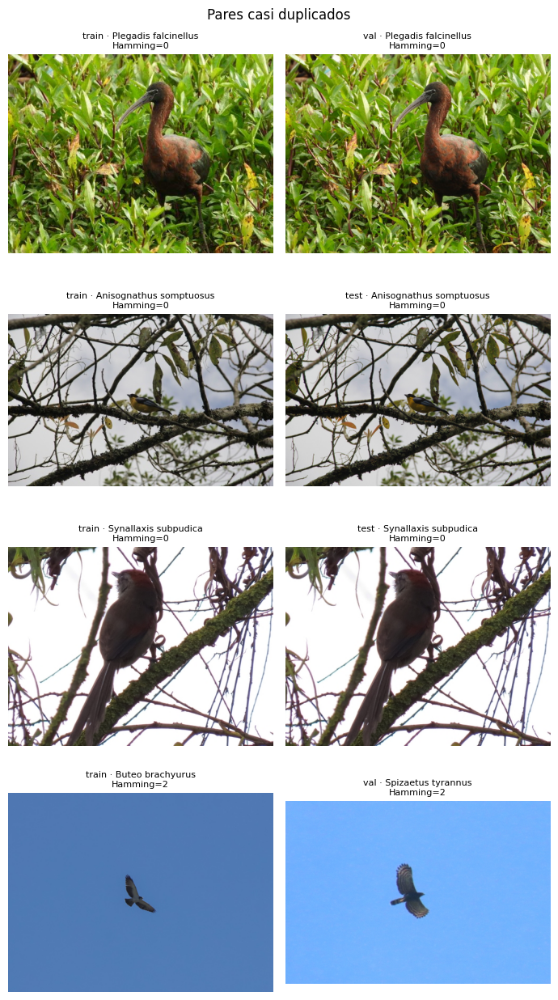

In [12]:
def show_pairs(df, n=4, title="Pares casi duplicados"):
    if df is None or len(df) == 0:
        print("Sin pares para mostrar.")
        return
    df = df.head(n)
    fig, axes = plt.subplots(len(df), 2, figsize=(7, 3.2 * len(df)))
    axes = np.atleast_2d(axes)
    for k, (_, r) in enumerate(df.iterrows()):
        for j, side in enumerate(("a", "b")):
            axes[k, j].imshow(load_rgb(r[f"path_{side}"]))
            axes[k, j].set_title(f"{r[f'split_{side}']} · {r[f'especie_{side}']}\nHamming={r['hamming']}", fontsize=8)
            axes[k, j].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


if len(near_dup_df):
    show_pairs(near_dup_df[~near_dup_df["md5_igual"]].sort_values("hamming"), n=4)

## 9. Análisis exploratorio del dataset


**Qué buscamos:**
- **Desbalance**: razón máx/mín de imágenes por clase en train. Como regla práctica: < 3 leve, 3–10 moderado, > 10 severo.
- **Tamaño de val/test por clase**: con ~8 imágenes de test por especie, cada acierto o error mueve la accuracy de esa clase en **12.5 puntos**. Las métricas por clase serán inestables.
- **Resoluciones**: si la mayoría de las imágenes son mucho mayores que 256 px, la caché redimensionada ahorra mucho tiempo.
- **Coherencia con `n_test` del CSV**: diferencias indican que el test actual no es el mismo usado para el baseline.

,total,mín/clase,mediana/clase,máx/clase,razón máx/mín
split,,,,,
train,2584,34,34.0,34,1.00
val,606,7,8.0,8,1.14
test,596,7,8.0,8,1.14


Desbalance en train: razón 1.00 → leve


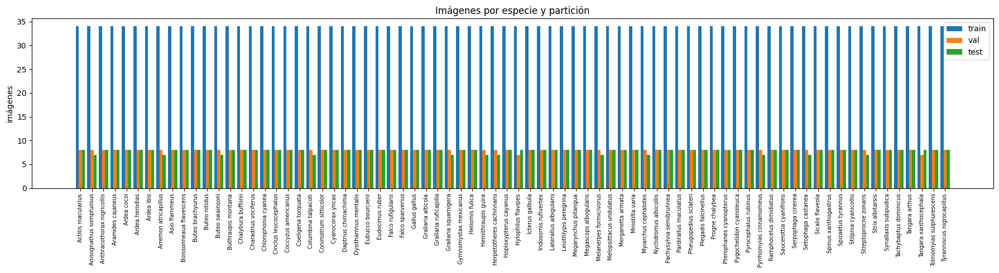

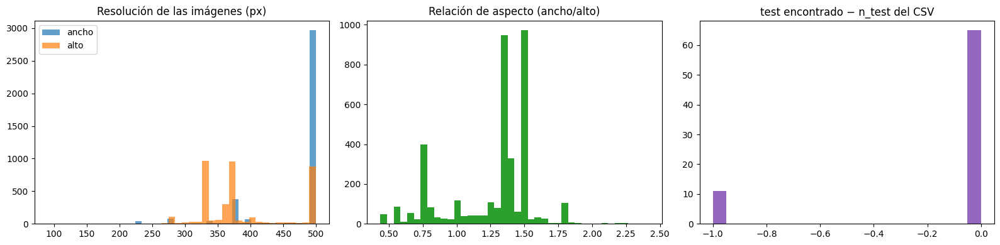

Lado corto mediano: 375 px
Especies cuyo test difiere de n_test del CSV: 11 de 76


In [13]:
def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")


cnt = images_df.groupby(["especie", "split"]).size().unstack(fill_value=0).reindex(
    index=CLASS_NAMES, columns=list(SPLITS), fill_value=0)
summary = pd.DataFrame({
    "total": cnt.sum(), "mín/clase": cnt.min(), "mediana/clase": cnt.median(),
    "máx/clase": cnt.max(), "razón máx/mín": (cnt.max() / cnt.min().clip(lower=1)).round(2)})
display(summary)
imb_ratio = summary.loc["train", "razón máx/mín"]
level = "leve" if imb_ratio < 3 else ("moderado" if imb_ratio <= 10 else "severo")
print(f"Desbalance en train: razón {imb_ratio:.2f} → {level}")

fig, ax = plt.subplots(figsize=(18, 5))
order = cnt["train"].sort_values(ascending=False).index
x = np.arange(len(order))
ax.bar(x - 0.27, cnt.loc[order, "train"], width=0.27, label="train")
ax.bar(x, cnt.loc[order, "val"], width=0.27, label="val")
ax.bar(x + 0.27, cnt.loc[order, "test"], width=0.27, label="test")
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=90, fontsize=7)
ax.set_ylabel("imágenes")
ax.set_title("Imágenes por especie y partición")
ax.legend()
plt.tight_layout()
savefig(fig, "eda_conteos")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(images_df["width"], bins=40, alpha=.7, label="ancho")
axes[0].hist(images_df["height"], bins=40, alpha=.7, label="alto")
axes[0].set_title("Resolución de las imágenes (px)")
axes[0].legend()
axes[1].hist(images_df["width"] / images_df["height"], bins=40, color="tab:green")
axes[1].set_title("Relación de aspecto (ancho/alto)")
cmp = cnt["test"] - pd.Series(sp_info.loc[CLASS_NAMES, "n_test"].astype(float).values, index=CLASS_NAMES)
axes[2].hist(cmp, bins=20, color="tab:purple")
axes[2].set_title("test encontrado − n_test del CSV")
plt.tight_layout()
savefig(fig, "eda_resolucion")
plt.show()
print(f"Lado corto mediano: {np.median(np.minimum(images_df['width'], images_df['height'])):.0f} px")
print(f"Especies cuyo test difiere de n_test del CSV: {(cmp != 0).sum()} de {NUM_CLASSES}")

## 10. Visualización de muestras

Una imagen aleatoria de 20 especies de `train`. Sirve para detectar a simple vista problemas de etiquetado, imágenes que no son aves (huellas, nidos, sonogramas), fondos dominantes o aves muy pequeñas en el encuadre — situaciones frecuentes en iNaturalist que limitan el rendimiento alcanzable.

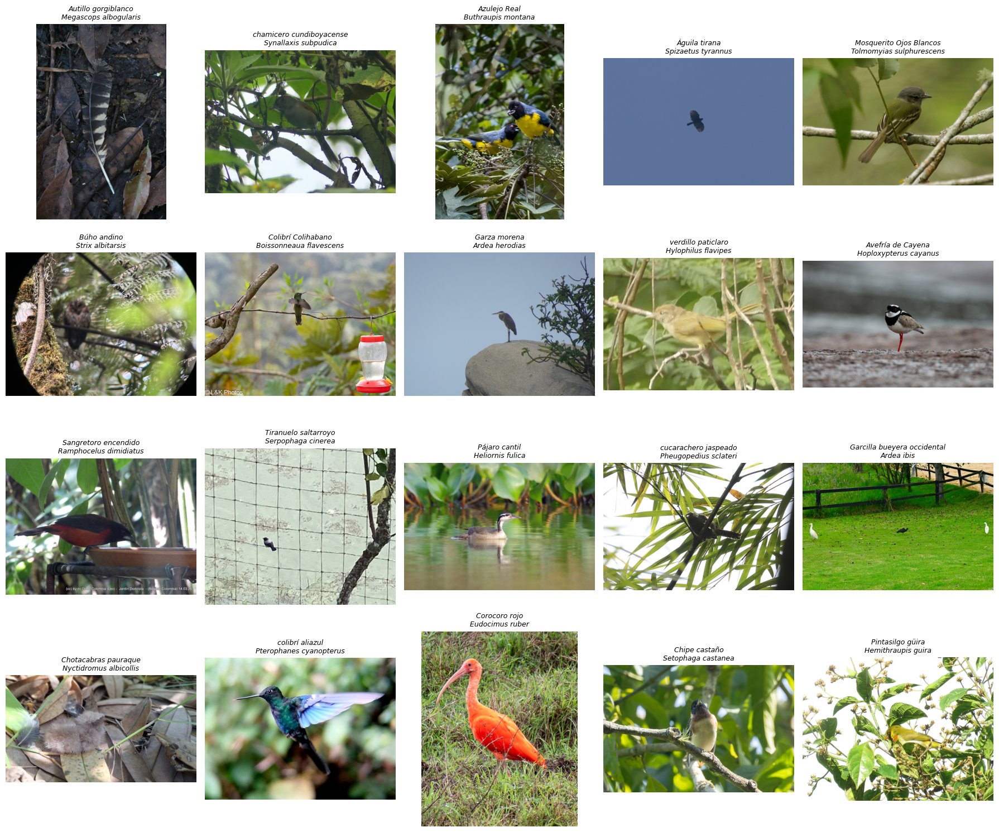

In [14]:
rng = np.random.default_rng(RANDOM_SEED)
sample_classes = rng.choice(CLASS_NAMES, size=min(20, NUM_CLASSES), replace=False)
fig, axes = plt.subplots(4, 5, figsize=(18, 15))
for ax, sp in zip(axes.ravel(), sample_classes):
    row = images_df[(images_df["split"] == "train") & (images_df["especie"] == sp)].sample(1, random_state=RANDOM_SEED).iloc[0]
    ax.imshow(load_rgb(row["path"]))
    ax.set_title(f"{sci_to_common[sp]}\n{sp}", fontsize=9, style="italic")
    ax.axis("off")
for ax in axes.ravel()[len(sample_classes):]:
    ax.axis("off")
plt.tight_layout()
savefig(fig, "muestras_train")
plt.show()

## 11. Data augmentation

**Qué:** transformaciones aleatorias aplicadas *solo* a train para que el modelo vea variaciones plausibles de cada foto y generalice mejor. Val y test usan una transformación **determinista** (redimensionar el lado corto a `1.14 × tamaño` y recortar el centro), de modo que las métricas sean comparables entre épocas y trials.

| Transformación | light | medium | strong | Por qué es seguro para aves |
|---|---|---|---|---|
| `RandomResizedCrop` (escala mínima) | 0.60 | 0.45 | 0.35 | Simula distancia/encuadre; escalas menores arriesgan recortar el ave |
| Flip horizontal | ✔ | ✔ | ✔ | Las aves son aproximadamente simétricas lateralmente |
| Rotación (p=0.5) | ±10° | ±15° | ±20° | Posturas en ramas; sin rotaciones extremas |
| ColorJitter (p=0.7) brillo/contraste/saturación | 0.15/0.15/0.10 | 0.20/0.20/0.15 | 0.25/0.25/0.20 | Iluminación variable |
| ColorJitter **hue** | 0 | 0.02 | 0.03 | Casi nulo: el color del plumaje es diagnóstico (p. ej. tángaras) |
| RandAugment (2 ops, magnitud 7) | ✘ | ✘ | ✔ | Política automática de intensidad moderada |
| RandomErasing | 0.10 | 0.20 | 0.25 | Simula oclusiones (hojas, ramas) |

**Excluido a propósito:** flip vertical, rotaciones > 30°, cambios de matiz fuertes, escala de grises, distorsiones geométricas fuertes (alteran silueta y forma del pico).

**Efecto esperado:** más augmentation → menos sobreajuste pero convergencia más lenta. Con pocos datos por clase suele convenir `medium`; Optuna decide entre los tres niveles usando Macro F1 de validación.

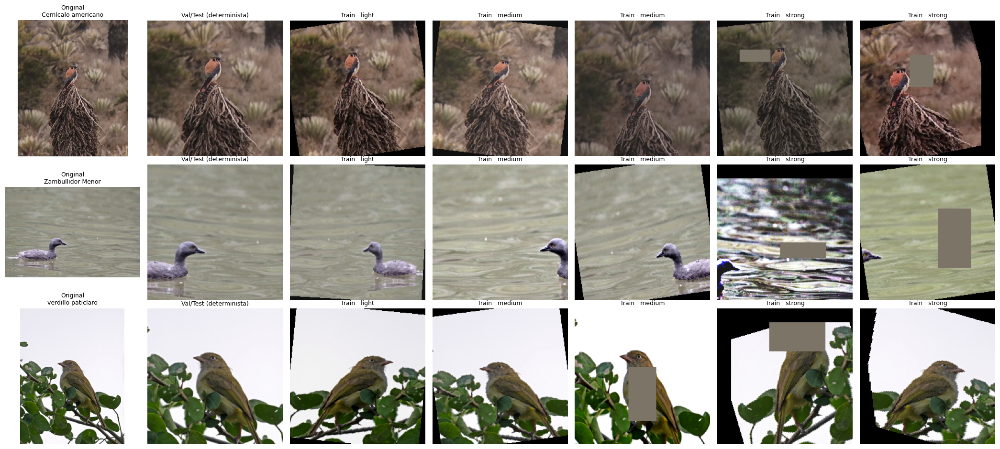

In [15]:
def denormalize(t, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    t = t.detach().cpu().float() * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)
    return t.clamp(0, 1).permute(1, 2, 0).numpy()


demo_rows = images_df[images_df["split"] == "train"].sample(3, random_state=RANDOM_SEED)
eval_tf_demo = build_eval_transform(IMAGE_SIZE)
fig, axes = plt.subplots(3, 7, figsize=(21, 9.5))
for r, (_, row) in enumerate(demo_rows.iterrows()):
    img = load_rgb(row["path"])
    axes[r, 0].imshow(img)
    axes[r, 0].set_title(f"Original\n{sci_to_common[row['especie']]}", fontsize=9)
    axes[r, 1].imshow(denormalize(eval_tf_demo(img)))
    axes[r, 1].set_title("Val/Test (determinista)", fontsize=9)
    for c, level in enumerate(["light", "medium", "medium", "strong", "strong"], start=2):
        axes[r, c].imshow(denormalize(build_train_transform(IMAGE_SIZE, level)(img)))
        axes[r, c].set_title(f"Train · {level}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
savefig(fig, "augmentation_ejemplos")
plt.show()

## 12. Construcción de DataLoaders

### 12.1 Caché redimensionada
Si `USE_RESIZED_CACHE=True`, cada imagen válida se guarda una sola vez en `outputs_aves76/cache_320/<split>/<carpeta>/` con su lado corto reducido a 320 px (JPEG calidad 95). Las imágenes más pequeñas se copian sin ampliar. **Los originales no se modifican.** La primera ejecución tarda unos minutos; las siguientes reutilizan la caché.

### 12.2 Desbalance de clases: cuándo usar cada estrategia
| Estrategia | Cómo actúa | Cuándo conviene | Riesgo |
|---|---|---|---|
| `none` (+ label smoothing) | Pérdida estándar | Desbalance leve (razón < 3) | Clases raras con menor recall |
| `sampler` (`WeightedRandomSampler`) | Muestrea clases raras más a menudo; cada batch está más equilibrado | Desbalance moderado/severo con suficiente augmentation | Repite mucho las mismas imágenes raras → sobreajuste en ellas |
| `class_weights` (CE ponderada) | Penaliza más los errores en clases raras; pesos = (1/frecuencia)^`CLASS_WEIGHT_POWER` | Desbalance moderado; mantiene la distribución natural de los batches | Pesos extremos → gradientes ruidosos (por eso la potencia 0.5) |
| `focal` | Reduce la pérdida de ejemplos ya bien clasificados (factor $(1-p_t)^\gamma$) | Muchas clases visualmente parecidas, ejemplos "difíciles" | Puede ralentizar la convergencia; combina mal con label smoothing alto |

### 12.3 Parámetros de eficiencia
- `pin_memory=True` (solo CUDA): copia host→GPU más rápida y asíncrona (`non_blocking=True`).
- `persistent_workers=True`: los workers sobreviven entre épocas; en Windows evita relanzar procesos (cada lanzamiento cuesta segundos).
- `drop_last=True` en train: evita un último batch diminuto que desestabiliza BatchNorm.

In [16]:
def cache_path_for(path_str: str) -> Path:
    p = Path(path_str)
    rel = p.relative_to(DATASET_ROOT)
    return CACHE_DIR / rel.parent / f"{p.stem}__{p.suffix.lstrip('.').lower()}.jpg"


def make_cached_copy(path_str: str):
    dst = cache_path_for(path_str)
    if dst.exists():
        return str(dst), None
    try:
        img = load_rgb(path_str)
        w, h = img.size
        scale = CACHE_SHORT_SIDE / min(w, h)
        if scale < 1:
            img = img.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.BICUBIC)
        dst.parent.mkdir(parents=True, exist_ok=True)
        tmp = dst.with_suffix(".tmp")
        img.save(tmp, format="JPEG", quality=95)
        os.replace(tmp, dst)
        return str(dst), None
    except Exception as e:
        return path_str, f"{type(e).__name__}: {e}"   # si falla, se usa el original


if USE_RESIZED_CACHE:
    with ThreadPoolExecutor(max_workers=8) as ex:
        results = list(tqdm(ex.map(make_cached_copy, images_df["path"]), total=len(images_df), desc="Caché redimensionada"))
    images_df["load_path"] = [r[0] for r in results]
    cache_errors = [r[1] for r in results if r[1]]
    if cache_errors:
        print(f"⚠️  {len(cache_errors)} imágenes no se pudieron cachear; se usarán los originales. Ej.: {cache_errors[:3]}")
    print("Caché lista en:", CACHE_DIR)
else:
    images_df["load_path"] = images_df["path"]

train_df = images_df[images_df["split"] == "train"].reset_index(drop=True)
val_df = images_df[images_df["split"] == "val"].reset_index(drop=True)
test_df = images_df[images_df["split"] == "test"].reset_index(drop=True)   # NO se usa hasta la sección 19
print(f"train: {len(train_df):,} | val: {len(val_df):,} | test: {len(test_df):,} imágenes")

train_class_counts = np.bincount(train_df["label"], minlength=NUM_CLASSES)
if (train_class_counts == 0).any():
    raise RuntimeError(f"Clases sin imágenes en train: {[CLASS_NAMES[i] for i in np.where(train_class_counts == 0)[0]]}")


def compute_class_weights(counts: np.ndarray, power: float = CLASS_WEIGHT_POWER) -> torch.Tensor:
    w = (1.0 / counts.astype(np.float64)) ** power
    w = w / (w * counts).sum() * counts.sum()      # media ponderada por frecuencia = 1
    return torch.tensor(w, dtype=torch.float32)


CLASS_WEIGHTS = compute_class_weights(train_class_counts)
print(f"Pesos por clase (potencia {CLASS_WEIGHT_POWER}): mín {CLASS_WEIGHTS.min():.2f} | máx {CLASS_WEIGHTS.max():.2f}")


def make_loader(df, transform, batch_size, shuffle=False, sampler=None, drop_last=False,
                num_workers=None, seed=RANDOM_SEED):
    num_workers = NUM_WORKERS if num_workers is None else num_workers
    ds = BirdDataset(df["load_path"].tolist(), df["label"].tolist(), transform)
    kwargs = dict(batch_size=batch_size, shuffle=(shuffle and sampler is None), sampler=sampler,
                  num_workers=num_workers, pin_memory=(DEVICE.type == "cuda"),
                  drop_last=(drop_last and len(ds) > batch_size), generator=make_generator(seed))
    if num_workers > 0:
        kwargs.update(worker_init_fn=seed_worker, persistent_workers=True, prefetch_factor=2)
    return DataLoader(ds, **kwargs)


def build_loaders(image_size, batch_size, aug_level, imbalance_strategy, seed=RANDOM_SEED):
    """DataLoaders de train y val. El de test se construye solo en la evaluación final."""
    sampler = None
    if imbalance_strategy == "sampler":
        sample_w = (1.0 / train_class_counts)[train_df["label"].values]
        sampler = WeightedRandomSampler(torch.as_tensor(sample_w, dtype=torch.double), num_samples=len(train_df),
                                        replacement=True, generator=make_generator(seed))
    train_loader = make_loader(train_df, build_train_transform(image_size, aug_level), batch_size,
                               shuffle=True, sampler=sampler, drop_last=True, seed=seed)
    val_loader = make_loader(val_df, build_eval_transform(image_size), batch_size * 2, seed=seed)
    return train_loader, val_loader


def shutdown_loader(loader):
    """Cierra explícitamente los workers persistentes (evita procesos huérfanos entre trials)."""
    it = getattr(loader, "_iterator", None)
    if it is not None and hasattr(it, "_shutdown_workers"):
        try:
            it._shutdown_workers()
        except Exception:
            pass


# Benchmark de la carga de datos (solo CPU): si es más lenta que la GPU, la GPU esperará.
_tl, _vl = build_loaders(IMAGE_SIZE, BATCH_SIZE, "medium", "none")
t0, n_img = time.time(), 0
for i, (xb, yb) in enumerate(_tl):
    if i == 0:
        t0 = time.time()               # ignora el arranque de los workers
    else:
        n_img += xb.shape[0]
    if i >= (5 if QUICK_MODE else 30):
        break
loader_ips = max(n_img / max(time.time() - t0, 1e-6), 1.0)
print(f"Batch de ejemplo: {tuple(xb.shape)} | etiquetas: {yb[:8].tolist()}")
print(f"Velocidad de carga con {NUM_WORKERS} workers: ~{loader_ips:,.0f} img/s "
      f"(≈ {len(train_df) / max(loader_ips, 1):.1f} s por época solo en lectura y augmentation)")
shutdown_loader(_tl); shutdown_loader(_vl)
del _tl, _vl, xb, yb

Caché redimensionada:   0%|          | 0/3786 [00:00<?, ?it/s]

Caché lista en: c:\Users\User\Desktop\CNN - Aves\outputs_aves76\cache_320
train: 2,584 | val: 606 | test: 596 imágenes
Pesos por clase (potencia 0.5): mín 1.00 | máx 1.00
Batch de ejemplo: (32, 3, 224, 224) | etiquetas: [71, 2, 19, 24, 53, 69, 9, 5]
Velocidad de carga con 4 workers: ~934 img/s (≈ 2.8 s por época solo en lectura y augmentation)


### 12.4 Funciones de pérdida

- **CrossEntropy con label smoothing** ($\varepsilon$): reemplaza la etiqueta *one-hot* por $1-\varepsilon$ en la clase correcta y $\varepsilon/(K-1)$ en las demás. Evita que el modelo se vuelva sobreconfiado; útil cuando hay especies muy parecidas o etiquetas ruidosas. Valores típicos: 0.05–0.15.
- **Focal loss**: $\mathcal{L} = -(1-p_t)^{\gamma}\,\log p_t$. Con $\gamma=2$, un ejemplo con $p_t=0.9$ pesa 100 veces menos que con CE estándar; el entrenamiento se concentra en los ejemplos difíciles.

In [17]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None, label_smoothing=0.0):
        super().__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing
        self.register_buffer("weight", weight if weight is not None else None)

    def forward(self, logits, target):
        logits = logits.float()                          # estabilidad numérica con AMP
        ce = F.cross_entropy(logits, target, weight=self.weight, reduction="none",
                             label_smoothing=self.label_smoothing)
        pt = F.softmax(logits, dim=1).gather(1, target.unsqueeze(1)).squeeze(1)
        return ((1.0 - pt) ** self.gamma * ce).mean()


def make_criterion(imbalance_strategy, label_smoothing):
    if imbalance_strategy == "class_weights":
        return nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE), label_smoothing=label_smoothing)
    if imbalance_strategy == "focal":
        return FocalLoss(gamma=FOCAL_GAMMA, label_smoothing=label_smoothing).to(DEVICE)
    if imbalance_strategy in ("none", "sampler"):
        return nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    raise ValueError(f"Estrategia de desbalance desconocida: {imbalance_strategy}")

## 13. CNN baseline desde cero

Esta red sirve como **referencia pedagógica y experimental**: muestra cuánto aporta el preentrenamiento. No se asume que vaya a perder; se compara con las mismas métricas de validación.

### 13.1 Conceptos

**Convolución.** Un filtro (kernel) de tamaño $k\times k\times C_{in}$ se desliza sobre la imagen y en cada posición calcula un producto punto más un sesgo. Cada filtro aprende a detectar un patrón (borde, textura de plumas, ojo). Una capa con $C_{out}$ filtros produce $C_{out}$ mapas de activación.
$$\text{parámetros} = (k \cdot k \cdot C_{in} + 1)\cdot C_{out}$$

**Número de filtros.** Más filtros → más patrones detectables y más memoria/cómputo. Se duplican en cada bloque (32→64→128→256) porque, al reducir la resolución espacial, cada posición resume un área mayor y necesita más canales para describirla.

**Tamaño del kernel.** 3×3 es el estándar (dos 3×3 seguidas ven lo mismo que una 5×5 con menos parámetros y más no linealidad). 5×5 amplía el campo receptivo de inmediato, con ≈2.8× más parámetros.

**Stride.** Paso con el que se desplaza el filtro. Stride 2 reduce el tamaño espacial a la mitad (submuestreo aprendido) y ahorra cómputo en las capas siguientes.

**Zero padding.** Añadir ceros alrededor de la entrada. Con `padding="same"` ($p=\lfloor k/2\rfloor$) se conserva el tamaño y se procesan bien los bordes; con `"valid"` ($p=0$) cada convolución recorta $k-1$ píxeles.
$$\text{salida} = \left\lfloor \frac{\text{entrada} + 2p - k}{s} \right\rfloor + 1$$

**Pooling.** Resume regiones pequeñas: *max pooling* conserva la activación más fuerte (¿está el patrón presente?), *average pooling* el promedio (más suave). Reduce la resolución, aporta algo de invariancia a pequeñas traslaciones y no tiene parámetros. Un kernel de 3 con stride 2 produce *overlapping pooling*.

**Batch normalization.** Normaliza cada canal con la media y varianza del batch y luego aplica una escala y un desplazamiento aprendibles. Estabiliza y acelera el entrenamiento y permite tasas de aprendizaje mayores. Con batches muy pequeños (< 8) sus estadísticas se vuelven ruidosas.

**Dropout.** Durante el entrenamiento apaga aleatoriamente una fracción $p$ de neuronas, obligando a la red a no depender de unas pocas; es regularización. `Dropout2d` apaga canales completos (más adecuado en convoluciones). En inferencia se desactiva.

**Capas densas / MLP.** Tras el *global average pooling* cada imagen es un vector; un perceptrón multicapa (Linear → ReLU → Dropout → … → Linear) combina esas características y produce los 76 *logits* (puntuaciones antes del softmax).

### 13.2 Arquitectura
`[Conv(k, stride s₁) → BN → ReLU → Conv(k) → BN → ReLU → Pool → Dropout2d] × n_bloques → GlobalAvgPool → MLP → 76 logits`

Al construir la red se ejecuta una pasada con una imagen ficticia para verificar que las dimensiones no colapsan a cero (posible con `padding="valid"`, kernel 5 y muchos bloques). Si colapsan, Optuna descarta la combinación.

In [18]:
class InvalidArchitectureError(ValueError):
    """Combinación de hiperparámetros que produce dimensiones imposibles (se descarta en Optuna)."""


class ConvBlock(nn.Module):
    def __init__(self, c_in, c_out, kernel_size, padding_mode, pool_type, pool_kernel, conv_dropout, stride=1):
        super().__init__()
        pad = kernel_size // 2 if padding_mode == "same" else 0
        self.conv1 = nn.Conv2d(c_in, c_out, kernel_size, stride=stride, padding=pad, bias=False)  # bias redundante con BN
        self.bn1 = nn.BatchNorm2d(c_out)
        self.act1 = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(c_out, c_out, kernel_size, stride=1, padding=pad, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.act2 = nn.ReLU(inplace=False)      # no in-place: aquí se engancha Grad-CAM
        pool_pad = pool_kernel // 2 if pool_kernel % 2 == 1 else 0
        Pool = nn.MaxPool2d if pool_type == "max" else nn.AvgPool2d
        self.pool = Pool(kernel_size=pool_kernel, stride=2, padding=pool_pad)
        self.drop = nn.Dropout2d(conv_dropout) if conv_dropout > 0 else nn.Identity()

    def forward(self, x):
        x = self.act1(self.bn1(self.conv1(x)))
        x = self.act2(self.bn2(self.conv2(x)))
        return self.drop(self.pool(x))


class ScratchCNN(nn.Module):
    def __init__(self, num_classes, image_size=224, n_blocks=4, base_filters=32, kernel_size=3,
                 padding_mode="same", pool_type="max", pool_kernel=2, first_stride=2,
                 dense_units=(256,), dropout=0.3, conv_dropout=0.1, max_filters=256):
        super().__init__()
        self.arch = "scratch_cnn"
        blocks, c_in = [], 3
        for i in range(n_blocks):
            c_out = min(base_filters * 2 ** i, max_filters)
            blocks.append(ConvBlock(c_in, c_out, kernel_size, padding_mode, pool_type, pool_kernel,
                                    conv_dropout, stride=first_stride if i == 0 else 1))
            c_in = c_out
        self.features = nn.Sequential(*blocks)
        self.gap = nn.AdaptiveAvgPool2d(1)
        mlp, d = [nn.Flatten()], c_in
        for units in dense_units:
            mlp += [nn.Linear(d, units), nn.ReLU(inplace=True), nn.Dropout(dropout)]
            d = units
        mlp.append(nn.Linear(d, num_classes))
        self.head = nn.Sequential(*mlp)

        # Verificación de dimensiones con una imagen ficticia
        try:
            with torch.no_grad():
                self.eval()
                fmap = self.features(torch.zeros(1, 3, image_size, image_size))
                self.train()
        except RuntimeError as e:
            raise InvalidArchitectureError(f"Configuración inválida: el mapa de características colapsa ({e})") from e
        if min(fmap.shape[-2:]) < 1:
            raise InvalidArchitectureError(f"Mapa de características vacío: {tuple(fmap.shape)}")
        self.feature_shape = tuple(fmap.shape[1:])

    def forward(self, x):
        return self.head(self.gap(self.features(x)))

    def get_gradcam_layer(self):
        return self.features[-1].act2


def summarize_shapes(model, image_size):
    """Tabla capa a capa: tipo, forma de salida y parámetros (útil para explicar la CNN)."""
    rows, hooks = [], []
    leaf_types = (nn.Conv2d, nn.BatchNorm2d, nn.ReLU, nn.MaxPool2d, nn.AvgPool2d, nn.Dropout2d,
                  nn.AdaptiveAvgPool2d, nn.Flatten, nn.Linear, nn.Dropout)
    for name, m in model.named_modules():
        if isinstance(m, leaf_types):
            def hook(mod, inp, out, name=name):
                extra = ""
                if isinstance(mod, nn.Conv2d):
                    extra = f"k={mod.kernel_size[0]} s={mod.stride[0]} p={mod.padding[0]}"
                elif isinstance(mod, (nn.MaxPool2d, nn.AvgPool2d)):
                    extra = f"k={mod.kernel_size} s={mod.stride}"
                rows.append({"capa": name, "tipo": type(mod).__name__, "detalle": extra,
                             "salida": tuple(out.shape[1:]),
                             "parámetros": sum(p.numel() for p in mod.parameters(recurse=False))})
            hooks.append(m.register_forward_hook(hook))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, image_size, image_size, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks:
        h.remove()
    return pd.DataFrame(rows)


demo_cnn = ScratchCNN(NUM_CLASSES, image_size=224)
shape_table = summarize_shapes(demo_cnn, 224)
display(shape_table)
print(f"Parámetros totales: {sum(p.numel() for p in demo_cnn.parameters()):,} | "
      f"mapa final antes del GAP: {demo_cnn.feature_shape}")
del demo_cnn

,capa,tipo,detalle,salida,parámetros
0,features.0.conv1,Conv2d,k=3 s=2 p=1,"(32, 112, 112)",864
1,features.0.bn1,BatchNorm2d,,"(32, 112, 112)",64
2,features.0.act1,ReLU,,"(32, 112, 112)",0
3,features.0.conv2,Conv2d,k=3 s=1 p=1,"(32, 112, 112)",9216
4,features.0.bn2,BatchNorm2d,,"(32, 112, 112)",64
5,features.0.act2,ReLU,,"(32, 112, 112)",0
6,features.0.pool,MaxPool2d,k=2 s=2,"(32, 56, 56)",0
7,features.0.drop,Dropout2d,,"(32, 56, 56)",0
8,features.1.conv1,Conv2d,k=3 s=1 p=1,"(64, 56, 56)",18432
9,features.1.bn1,BatchNorm2d,,"(64, 56, 56)",128


Parámetros totales: 1,258,540 | mapa final antes del GAP: (256, 7, 7)


## 14. Modelos preentrenados

### 14.1 Transfer learning y fine-tuning
**Transfer learning:** reutilizar una red entrenada en ImageNet (1.28 M imágenes, 1 000 clases, de las cuales ~60 son aves) como extractor de características. Las primeras capas detectan bordes y texturas genéricas; las últimas, partes de objetos. Se sustituye la cabeza de 1 000 clases por una nueva de 76.

**Fase 1 — cabeza:** backbone congelado; solo se entrena la cabeza nueva. Evita que los gradientes grandes y aleatorios de una cabeza sin entrenar destruyan los pesos preentrenados. Además, las capas BatchNorm congeladas se mantienen en modo evaluación para no alterar sus estadísticas de ImageNet.

**Fase 2 — fine-tuning progresivo:** se descongelan los últimos `n_unfreeze` bloques, uno o varios por época, hasta completarlos a mitad de la fase. El backbone usa una tasa de aprendizaje menor (`lr_backbone`, típicamente 10–30× menor que `lr_head`): debe *ajustarse*, no reaprenderse.

### 14.2 Arquitecturas
| Modelo | Idea principal | Bloques para descongelar (de la salida hacia la entrada) |
|---|---|---|
| **EfficientNet-B0** | Escalado compuesto de ancho/profundidad/resolución; bloques MBConv con *squeeze-excitation*. Muy eficiente | 9 (`features[8]`, `features[7]`, …) |
| **ConvNeXt-Tiny** | CNN "modernizada" con ideas de los Transformers: kernels 7×7, LayerNorm, GELU. Fuerte en clasificación fina | 5 (stage 4, stage 3, stage 2, stage 1, stem) |
| **ResNet50** | Conexiones residuales; referencia clásica y robusta | 5 (`layer4`, `layer3`, `layer2`, `layer1`, stem) |
| **EfficientNetV2-S** *(opcional)* | Fused-MBConv, entrenamiento progresivo; más pesado | 8 |

### 14.3 Cabeza MLP
`[Dropout → Linear(in, h) → GELU] × (1 o 2) → Dropout → Linear(·, 76)`. Con dos capas ocultas, la segunda tiene $h/2$ unidades.

> Los pesos de ImageNet se descargan **una sola vez** (≈20–100 MB por modelo) a `%USERPROFILE%\.cache\torch\hub\checkpoints`.

In [19]:
ARCH_SPECS = {
    "efficientnet_b0": (models.efficientnet_b0, models.EfficientNet_B0_Weights.IMAGENET1K_V1),
    "convnext_tiny": (models.convnext_tiny, models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1),
    "resnet50": (models.resnet50, models.ResNet50_Weights.IMAGENET1K_V2),
    "efficientnet_v2_s": (models.efficientnet_v2_s, models.EfficientNet_V2_S_Weights.IMAGENET1K_V1),
}
# Límite de batch por arquitectura y resolución para no exceder 8 GB (con AMP)
MAX_BATCH_BY_ARCH = {"efficientnet_v2_s": {224: 16, 256: 16}, "convnext_tiny": {224: 32, 256: 32}}


def build_head(in_features, num_classes, hidden_dim, n_hidden, dropout):
    layers, d = [], in_features
    for i in range(n_hidden):
        h = hidden_dim if i == 0 else max(hidden_dim // 2, 64)
        layers += [nn.Dropout(dropout), nn.Linear(d, h), nn.GELU()]
        d = h
    layers += [nn.Dropout(dropout), nn.Linear(d, num_classes)]
    return nn.Sequential(*layers)


class TransferNet(nn.Module):
    """Backbone preentrenado (sin su clasificador) + cabeza MLP nueva."""

    def __init__(self, arch, num_classes, hidden_dim=512, n_hidden=1, head_dropout=0.3, pretrained=True):
        super().__init__()
        if arch not in ARCH_SPECS:
            raise ValueError(f"Arquitectura no soportada: {arch}. Opciones: {list(ARCH_SPECS)}")
        self.arch = arch
        ctor, weights = ARCH_SPECS[arch]
        try:
            net = ctor(weights=weights if pretrained else None)
        except Exception as e:
            raise RuntimeError(
                f"No se pudieron cargar los pesos ImageNet de {arch}: {e}\n"
                "→ Verifica la conexión a internet (solo la primera vez) o copia el .pth a "
                "%USERPROFILE%\\.cache\\torch\\hub\\checkpoints") from e
        if arch.startswith("efficientnet"):
            in_f = net.classifier[1].in_features
            net.classifier = nn.Identity()
        elif arch == "convnext_tiny":
            in_f = net.classifier[2].in_features
            net.classifier[2] = nn.Identity()          # conserva LayerNorm2d + Flatten preentrenados
        elif arch == "resnet50":
            in_f = net.fc.in_features
            net.fc = nn.Identity()
        self.backbone = net
        self.head = build_head(in_f, num_classes, hidden_dim, n_hidden, head_dropout)
        self.in_features = in_f

    def forward(self, x):
        return self.head(self.backbone(x))

    def backbone_blocks(self):
        """Grupos de módulos ordenados de la entrada a la salida (para descongelar desde el final)."""
        b = self.backbone
        if self.arch.startswith("efficientnet"):
            return [[m] for m in b.features]
        if self.arch == "convnext_tiny":
            f = b.features
            return [[f[0]], [f[1]], [f[2], f[3]], [f[4], f[5]], [f[6], f[7], b.classifier[0]]]
        if self.arch == "resnet50":
            return [[b.conv1, b.bn1], [b.layer1], [b.layer2], [b.layer3], [b.layer4]]
        raise ValueError(self.arch)

    def get_gradcam_layer(self):
        b = self.backbone
        return b.layer4 if self.arch == "resnet50" else b.features[-1]


def set_requires_grad(modules, flag):
    for m in modules:
        for p in m.parameters():
            p.requires_grad = flag


def freeze_backbone(model):
    set_requires_grad([model.backbone], False)
    set_requires_grad([model.head], True)


def last_blocks_params(model, n):
    blocks = model.backbone_blocks()
    n = min(n, len(blocks))
    return [p for group in blocks[len(blocks) - n:] for m in group for p in m.parameters()]


def unfreeze_last_blocks(model, n):
    blocks = model.backbone_blocks()
    for group in blocks[len(blocks) - min(n, len(blocks)):]:
        set_requires_grad(group, True)


def set_frozen_bn_eval(model):
    """BatchNorm de capas congeladas en modo eval: conserva las estadísticas de ImageNet."""
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            if not any(p.requires_grad for p in m.parameters(recurse=False)):
                m.eval()


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))


arch_rows = []
for arch in CANDIDATE_ARCHS:
    m = TransferNet(arch, NUM_CLASSES)
    freeze_backbone(m)
    arch_rows.append({"arquitectura": arch, "parámetros totales (M)": count_params(m) / 1e6,
                      "entrenables fase 1 (M)": count_params(m, True) / 1e6,
                      "dim. características": m.in_features, "bloques descongelables": len(m.backbone_blocks())})
    del m
gc.collect()
pd.DataFrame(arch_rows).round(2)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to C:\Users\User/.cache\torch\hub\checkpoints\convnext_tiny-983f1562.pth
100%|██████████| 109M/109M [00:02<00:00, 50.7MB/s] 


,arquitectura,parámetros totales (M),entrenables fase 1 (M),dim. características,bloques descongelables
0,efficientnet_b0,4.70,0.69,1280,9
1,convnext_tiny,28.25,0.43,768,5
2,resnet50,24.60,1.09,2048,5


## 15. Funciones de entrenamiento y validación.

### 15.1 Métricas
| Métrica | Qué mide | Por qué importa aquí |
|---|---|---|
| **Macro F1** *(principal)* | Media simple del F1 de cada clase | Cada especie pesa lo mismo, tenga 20 o 200 imágenes. Un modelo que ignora las especies raras obtiene Macro F1 bajo aunque su accuracy sea alta |
| Accuracy | % de aciertos global | Dominada por las clases más frecuentes |
| Balanced accuracy | Media del recall por clase | Robusta al desbalance |
| Macro precision / recall | Media por clase de precisión / exhaustividad | Diagnóstico de falsos positivos vs. falsos negativos |
| Weighted F1 | F1 ponderado por soporte | Comparable con la accuracy |
| Top-3 / Top-5 | La clase real está entre las 3/5 más probables | Útil como asistente de identificación |
| Loss | Entropía cruzada | Calibración; si baja la loss de train y sube la de val → sobreajuste |

$$F1_c = \frac{2\,P_c R_c}{P_c + R_c}, \qquad \text{Macro F1} = \frac{1}{K}\sum_{c=1}^{K} F1_c$$

### 15.2 Bucle de entrenamiento
- **Mixed precision (`torch.autocast` + `GradScaler`)**: las operaciones adecuadas se ejecutan en FP16; el *scaler* multiplica la pérdida para evitar que gradientes pequeños se vuelvan cero en FP16.
- **Gradient accumulation**: suma gradientes de `k` mini-batches antes de actualizar; equivale a un batch `k` veces mayor con la misma VRAM.
- **Gradient clipping**: limita la norma del gradiente (1.0) para evitar actualizaciones explosivas, especialmente al descongelar bloques.
- **`channels_last`**: formato de memoria que aprovecha mejor los Tensor Cores en convoluciones con AMP.
- **Pesos sin *weight decay*** en sesgos y normalizaciones (práctica estándar con AdamW).

### 15.3 Early stopping
Se monitoriza el **Macro F1 de validación**. Si no mejora al menos `MIN_DELTA` durante `patience` épocas, el entrenamiento se detiene y se restauran los pesos de la mejor época. Durante la fase 1 (backbone congelado) no se cuenta paciencia: la fase 2 debe tener oportunidad de mejorar. **Nunca se usa test.**

### 15.4 Checkpoints y reanudación
En el entrenamiento final se guardan `best.pth` (mejor Macro F1) y `last.pth` (estado completo: pesos, optimizador, scheduler, scaler, historial y early stopping). Si la ejecución se interrumpe, al relanzarla con la misma configuración continúa desde la última época 

In [20]:
class VRAMExhaustedError(RuntimeError):
    """La VRAM se agotó incluso tras reducir el batch."""


def amp_enabled():
    return USE_AMP and DEVICE.type == "cuda"


def make_grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=amp_enabled())
    except (AttributeError, TypeError):            # PyTorch < 2.3
        return torch.cuda.amp.GradScaler(enabled=amp_enabled())


def is_oom(exc):
    return isinstance(exc, torch.cuda.OutOfMemoryError) or "out of memory" in str(exc).lower()


def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


def compute_metrics(y_true, probs):
    y_true = np.asarray(y_true)
    y_pred = probs.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    ranked = np.argsort(-probs, axis=1)
    topk = lambda k: float((ranked[:, :k] == y_true[:, None]).any(1).mean())
    return {"accuracy": accuracy_score(y_true, y_pred), "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_precision": p, "macro_recall": r, "macro_f1": f1,
            "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
            "top3_accuracy": topk(3), "top5_accuracy": topk(5)}


@torch.no_grad()
def evaluate(model, loader, criterion=None, max_batches=None, return_outputs=False):
    model.eval()
    probs_list, y_list, loss_sum, n = [], [], 0.0, 0
    for i, (x, y) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        x = x.to(DEVICE, non_blocking=True, memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp_enabled()):
            logits = model(x)
        logits = logits.float()
        if criterion is not None:
            loss_sum += criterion(logits, y).item() * y.size(0)
        probs_list.append(F.softmax(logits, dim=1).cpu().numpy())
        y_list.append(y.cpu().numpy())
        n += y.size(0)
    probs, y_true = np.concatenate(probs_list), np.concatenate(y_list)
    metrics = compute_metrics(y_true, probs)
    metrics["loss"] = loss_sum / max(n, 1)
    return (metrics, y_true, probs) if return_outputs else metrics


def make_optimizer(groups, name, weight_decay):
    """Separa en cada grupo los parámetros con y sin weight decay (sesgos y normalizaciones sin decay)."""
    param_groups = []
    for g in groups:
        decay = [p for p in g["params"] if p.ndim > 1]
        no_decay = [p for p in g["params"] if p.ndim <= 1]
        if decay:
            param_groups.append({"params": decay, "lr": g["lr"], "weight_decay": weight_decay, "name": g["name"]})
        if no_decay:
            param_groups.append({"params": no_decay, "lr": g["lr"], "weight_decay": 0.0, "name": g["name"]})
    if name == "adamw":
        return torch.optim.AdamW(param_groups, betas=(0.9, 0.999))
    if name == "sgd":
        return torch.optim.SGD(param_groups, momentum=0.9, nesterov=True)
    raise ValueError(f"Optimizador desconocido: {name}")


def make_scheduler(optimizer, name, steps_per_epoch, epochs):
    total = max(1, steps_per_epoch * max(1, epochs))
    if name == "cosine":
        warm = min(steps_per_epoch, total // 5)          # ~1 época de calentamiento
        def lr_lambda(step):
            if warm > 0 and step < warm:
                return (step + 1) / warm
            prog = min(1.0, (step - warm) / max(1, total - warm))
            return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * prog))
        return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda), "batch"
    if name == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(
            optimizer, max_lr=[g["lr"] for g in optimizer.param_groups], total_steps=total,
            pct_start=0.25, anneal_strategy="cos", div_factor=10, final_div_factor=100), "batch"
    if name == "plateau":
        return torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.3, patience=1), "epoch"
    raise ValueError(f"Scheduler desconocido: {name}")


def current_lrs(optimizer):
    lrs = {}
    for g in optimizer.param_groups:
        lrs.setdefault(g.get("name", "group"), g["lr"])
    return lrs


class EarlyStopping:
    def __init__(self, patience, min_delta=MIN_DELTA):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.ref, self.best_epoch, self.counter = -float("inf"), -float("inf"), -1, 0

    def step(self, score, epoch, can_stop=True):
        improved = score > self.best
        if improved:
            self.best, self.best_epoch = score, epoch
        if score > self.ref + self.min_delta:
            self.ref, self.counter = score, 0
        elif can_stop:
            self.counter += 1
        return improved, self.counter >= self.patience


def train_one_epoch(model, loader, criterion, optimizer, scaler, scheduler, sched_mode,
                    accum_steps=1, max_batches=None):
    model.train()
    set_frozen_bn_eval(model)
    n_batches = len(loader) if max_batches is None else min(len(loader), max_batches)
    optimizer.zero_grad(set_to_none=True)
    loss_sum = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)
    n = 0
    for i, (x, y) in enumerate(loader):
        if i >= n_batches:
            break
        x = x.to(DEVICE, non_blocking=True, memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp_enabled()):
            logits = model(x)
            loss = criterion(logits, y)
        if not torch.isfinite(loss):
            raise FloatingPointError("La pérdida es NaN/Inf: LR demasiado alto o inestabilidad numérica.")
        scaler.scale(loss / accum_steps).backward()
        if (i + 1) % accum_steps == 0 or (i + 1) == n_batches:
            if GRAD_CLIP_NORM:
                scaler.unscale_(optimizer)
                params = [p for g in optimizer.param_groups for p in g["params"] if p.grad is not None]
                if params:
                    torch.nn.utils.clip_grad_norm_(params, GRAD_CLIP_NORM)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            if sched_mode == "batch":
                try:
                    scheduler.step()
                except ValueError:      # OneCycle ya completó sus pasos
                    pass
        loss_sum += loss.detach() * y.size(0)
        correct += (logits.argmax(1) == y).sum()
        n += y.size(0)
    return {"loss": (loss_sum / max(n, 1)).item(), "accuracy": (correct / max(n, 1)).item()}

In [21]:
def fit(model, hp, train_loader, val_loader, epochs, phase1_epochs, patience, max_batches=None,
        trial=None, ckpt_dir=None, resume=False, keep_best=True, verbose=True):
    """Entrena con fase 1 (cabeza) + fase 2 (fine-tuning progresivo) o una sola fase (CNN desde cero)."""
    is_scratch = getattr(model, "arch", "") == "scratch_cnn"
    model.to(DEVICE)
    if DEVICE.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    criterion = make_criterion(hp["imbalance_strategy"], hp["label_smoothing"])
    scaler = make_grad_scaler()
    accum = int(hp.get("grad_accum", GRAD_ACCUM_STEPS))
    n_batches = len(train_loader) if max_batches is None else min(len(train_loader), max_batches)
    steps_per_epoch = math.ceil(n_batches / accum)
    phase1_epochs = 0 if is_scratch else min(phase1_epochs, epochs)
    phase2_epochs = epochs - phase1_epochs
    n_unfreeze = int(hp.get("n_unfreeze", 0))
    st = {"optimizer": None, "scheduler": None, "sched_mode": None, "phase": None}

    def phase_of(epoch):
        return 0 if is_scratch else (1 if epoch < phase1_epochs else 2)

    def setup_phase(phase):
        if phase == 0:
            set_requires_grad([model], True)
            groups = [{"name": "head", "params": list(model.parameters()), "lr": hp["lr_head"]}]
            n_ep = epochs
        else:
            freeze_backbone(model)
            groups = [{"name": "head", "params": list(model.head.parameters()), "lr": hp["lr_head"]}]
            n_ep = phase1_epochs
            if phase == 2:
                groups.append({"name": "backbone", "params": last_blocks_params(model, n_unfreeze),
                               "lr": hp["lr_backbone"]})
                n_ep = phase2_epochs
        opt = make_optimizer(groups, hp["optimizer"], hp["weight_decay"])
        sched, mode = make_scheduler(opt, hp["scheduler"], steps_per_epoch, n_ep)
        st.update(optimizer=opt, scheduler=sched, sched_mode=mode, phase=phase)

    def apply_unfreeze(epoch):
        """Descongela progresivamente: todos los bloques elegidos quedan activos a mitad de la fase 2."""
        if phase_of(epoch) != 2 or n_unfreeze == 0:
            return 0
        e2 = epoch - phase1_epochs
        per_epoch = math.ceil(n_unfreeze / max(1, phase2_epochs // 2))
        n_active = min(n_unfreeze, per_epoch * (e2 + 1))
        freeze_backbone(model)
        unfreeze_last_blocks(model, n_active)
        return n_active

    history, es, start_epoch, best_state = [], EarlyStopping(patience), 0, None
    best_path = last_path = None
    if ckpt_dir is not None:
        ckpt_dir = Path(ckpt_dir)
        ckpt_dir.mkdir(parents=True, exist_ok=True)
        best_path, last_path = ckpt_dir / "best.pth", ckpt_dir / "last.pth"

    # ---------- Reanudación ----------
    if resume and last_path is not None and last_path.exists():
        try:
            ck = torch.load(last_path, map_location=DEVICE, weights_only=False)
            if ck.get("hp") != hp or ck.get("epochs") != epochs or ck.get("phase1_epochs") != phase1_epochs:
                print("ℹ️  El checkpoint existente corresponde a otra configuración: se entrena desde cero.")
            else:
                model.load_state_dict(ck["model"])
                start_epoch = ck["epoch"]
                setup_phase(ck["phase"])
                apply_unfreeze(start_epoch - 1)
                st["optimizer"].load_state_dict(ck["optimizer"])
                st["scheduler"].load_state_dict(ck["scheduler"])
                scaler.load_state_dict(ck["scaler"])
                history = ck["history"]
                es.__dict__.update(ck["early_stopping"])
                if keep_best and best_path.exists():
                    best_state = torch.load(best_path, map_location="cpu", weights_only=False)["model"]
                print(f"🔁 Reanudando desde la época {start_epoch} (mejor Macro F1 hasta ahora: {es.best:.4f})")
        except Exception as e:
            print(f"⚠️  No se pudo cargar el checkpoint {last_path} ({type(e).__name__}: {e}). Se entrena desde cero.")
            history, es, start_epoch, best_state = [], EarlyStopping(patience), 0, None
            st["phase"] = None

    stop_now = es.counter >= es.patience and start_epoch > 0
    for epoch in range(start_epoch, epochs):
        if stop_now:
            break
        ph = phase_of(epoch)
        if ph != st["phase"]:
            setup_phase(ph)
        n_active = apply_unfreeze(epoch)
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        tr = train_one_epoch(model, train_loader, criterion, st["optimizer"], scaler, st["scheduler"],
                             st["sched_mode"], accum, max_batches)
        va = evaluate(model, val_loader, criterion, max_batches=max_batches)
        if st["sched_mode"] == "epoch":
            st["scheduler"].step(va["macro_f1"])
        lrs = current_lrs(st["optimizer"])
        rec = {"epoch": epoch + 1, "phase": ph, "unfrozen_blocks": n_active,
               "train_loss": tr["loss"], "train_accuracy": tr["accuracy"],
               **{f"val_{k}": v for k, v in va.items()},
               "lr_head": lrs.get("head", np.nan), "lr_backbone": lrs.get("backbone", np.nan),
               "time_s": time.time() - t0,
               "peak_vram_gb": torch.cuda.max_memory_allocated() / 1024**3 if DEVICE.type == "cuda" else 0.0}
        history.append(rec)
        improved, stop_now = es.step(va["macro_f1"], epoch, can_stop=(ph != 1))

        if improved and keep_best:
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            if best_path is not None:
                torch.save({"model": best_state, "hp": hp, "epoch": epoch + 1, "val_macro_f1": va["macro_f1"]}, best_path)
        if last_path is not None:
            torch.save({"model": model.state_dict(), "optimizer": st["optimizer"].state_dict(),
                        "scheduler": st["scheduler"].state_dict(), "scaler": scaler.state_dict(),
                        "epoch": epoch + 1, "phase": ph, "hp": hp, "epochs": epochs,
                        "phase1_epochs": phase1_epochs, "history": history,
                        "early_stopping": dict(es.__dict__)}, last_path)
        if verbose:
            print(f"Ép {epoch + 1:>2}/{epochs} | fase {ph} | bloques {n_active} | "
                  f"train loss {tr['loss']:.3f} acc {tr['accuracy']:.3f} | val loss {va['loss']:.3f} "
                  f"acc {va['accuracy']:.3f} macroF1 {va['macro_f1']:.4f} top5 {va['top5_accuracy']:.3f} | "
                  f"{rec['time_s']:.0f}s | VRAM {rec['peak_vram_gb']:.2f} GB{'  ★' if improved else ''}")
        if trial is not None:
            trial.report(va["macro_f1"], epoch)
            if trial.should_prune():
                raise optuna.TrialPruned(f"Podado en la época {epoch + 1} (macroF1={va['macro_f1']:.4f})")
        if stop_now and verbose:
            print(f"⏹️  Early stopping: {es.patience} épocas sin mejora > {es.min_delta}. "
                  f"Mejor época: {es.best_epoch + 1} (Macro F1 = {es.best:.4f})")

    if keep_best and best_state is not None:
        model.load_state_dict(best_state)
    return {"model": model, "best_val_macro_f1": es.best, "best_epoch": es.best_epoch + 1,
            "history": pd.DataFrame(history)}


def build_model_from_hp(hp, pretrained=True):
    if hp["arch"] == "scratch_cnn":
        return ScratchCNN(NUM_CLASSES, image_size=hp["image_size"], n_blocks=hp["n_blocks"],
                          base_filters=hp["base_filters"], kernel_size=hp["kernel_size"],
                          padding_mode=hp["padding_mode"], pool_type=hp["pool_type"],
                          pool_kernel=hp["pool_kernel"], first_stride=hp["first_stride"],
                          dense_units=tuple(hp["dense_units"]), dropout=hp["dropout"],
                          conv_dropout=hp["conv_dropout"])
    return TransferNet(hp["arch"], NUM_CLASSES, hidden_dim=hp["hidden_dim"], n_hidden=hp["n_hidden"],
                       head_dropout=hp["head_dropout"], pretrained=pretrained)


def run_experiment(hp, epochs, phase1_epochs, patience, trial=None, max_batches=None,
                   ckpt_dir=None, resume=False, keep_best=False, verbose=True):
    """Construye modelo y loaders, entrena y libera memoria. Ante OOM reintenta con batch/2 y acumulación x2."""
    hp = dict(hp)
    hp["grad_accum"] = int(hp.get("grad_accum", GRAD_ACCUM_STEPS))
    cap = MAX_BATCH_BY_ARCH.get(hp["arch"], {}).get(hp["image_size"])
    if cap and hp["batch_size"] > cap:          # mantiene el batch efectivo con acumulación
        hp["grad_accum"] *= hp["batch_size"] // cap
        hp["batch_size"] = cap
    attempts = 2 if OOM_RETRY else 1
    for attempt in range(attempts):
        train_loader = val_loader = model = None
        oom = False
        try:
            seed_everything(RANDOM_SEED, DETERMINISTIC)
            model = build_model_from_hp(hp)
            train_loader, val_loader = build_loaders(hp["image_size"], hp["batch_size"], hp["aug_level"],
                                                     hp["imbalance_strategy"])
            result = fit(model, hp, train_loader, val_loader, epochs, phase1_epochs, patience,
                         max_batches=max_batches, trial=trial, ckpt_dir=ckpt_dir, resume=resume,
                         keep_best=keep_best, verbose=verbose)
            result["hp"] = hp
            if not keep_best:
                result["model"] = None
            return result
        except Exception as e:
            if not is_oom(e):
                raise
            oom = True
        finally:
            for ld in (train_loader, val_loader):
                if ld is not None:
                    shutdown_loader(ld)
            del train_loader, val_loader
            if oom:
                model = None
            free_memory()
        if oom:
            if attempt < attempts - 1 and hp["batch_size"] > 8:
                print(f"⚠️  CUDA sin memoria con batch {hp['batch_size']} ({hp['arch']}, {hp['image_size']}px). "
                      f"Reintentando con batch {hp['batch_size'] // 2} y acumulación x2.")
                hp["batch_size"] //= 2
                hp["grad_accum"] *= 2
                continue
            raise VRAMExhaustedError(
                f"VRAM agotada con {hp['arch']} a {hp['image_size']}px y batch {hp['batch_size']}. "
                "→ Reduce BATCH_SIZE_CHOICES / IMAGE_SIZE_CHOICES, desactiva EfficientNetV2-S, "
                "cierra otras aplicaciones que usen la GPU o activa USE_AMP.")

### 15.5 Prueba de humo: VRAM y velocidad por arquitectura
Antes de lanzar Optuna se mide, con tensores sintéticos y **todo el modelo descongelado** (peor caso de memoria), el pico de VRAM y el rendimiento en img/s de cada arquitectura con la resolución y el batch máximos de la búsqueda. Con eso se estima la duración de una época, de un trial y del estudio completo. Si alguna combinación da `OOM`, reduce `BATCH_SIZE_CHOICES` o `IMAGE_SIZE_CHOICES`.

In [22]:
def benchmark_arch(arch, image_size, batch_size, n_steps=8):
    model = opt = scaler = None
    try:
        model = (ScratchCNN(NUM_CLASSES, image_size=image_size) if arch == "scratch_cnn"
                 else TransferNet(arch, NUM_CLASSES)).to(DEVICE)
        if DEVICE.type == "cuda":
            model = model.to(memory_format=torch.channels_last)
            torch.cuda.reset_peak_memory_stats()
        model.train()
        opt = torch.optim.AdamW(model.parameters(), lr=1e-4)
        scaler = make_grad_scaler()
        x = torch.randn(batch_size, 3, image_size, image_size, device=DEVICE).to(memory_format=torch.channels_last)
        y = torch.randint(0, NUM_CLASSES, (batch_size,), device=DEVICE)
        times = []
        for step in range(n_steps):
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            t0 = time.time()
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp_enabled()):
                loss = F.cross_entropy(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            opt.zero_grad(set_to_none=True)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            if step >= 2:                       # descarta calentamiento de cuDNN
                times.append(time.time() - t0)
        ips = batch_size / np.mean(times)
        vram = torch.cuda.max_memory_allocated() / 1024**3 if DEVICE.type == "cuda" else 0.0
        return {"arquitectura": arch, "img_size": image_size, "batch": batch_size,
                "img/s (GPU)": round(ips), "pico VRAM (GB)": round(vram, 2), "estado": "OK"}
    except Exception as e:
        if not is_oom(e):
            raise
        return {"arquitectura": arch, "img_size": image_size, "batch": batch_size,
                "img/s (GPU)": np.nan, "pico VRAM (GB)": np.nan, "estado": "OOM"}
    finally:
        del model, opt, scaler
        free_memory()


bench_rows = []
for arch in CANDIDATE_ARCHS + ["scratch_cnn"]:
    size = max(SCRATCH_IMAGE_SIZE_CHOICES if arch == "scratch_cnn" else IMAGE_SIZE_CHOICES)
    bs = min(max(BATCH_SIZE_CHOICES), MAX_BATCH_BY_ARCH.get(arch, {}).get(size, 999))
    bench_rows.append(benchmark_arch(arch, size, bs, n_steps=4 if QUICK_MODE else 8))
bench_df = pd.DataFrame(bench_rows)

eff_ips = np.minimum(bench_df["img/s (GPU)"].fillna(1), loader_ips)   # el más lento de GPU y CPU manda
val_factor = 1 + 0.4 * len(val_df) / max(len(train_df), 1)            # validación ≈ 1/3 del coste por imagen
bench_df["época estimada (s)"] = (len(train_df) / eff_ips * val_factor).round(1)
bench_df["trial estimado (min)"] = (bench_df["época estimada (s)"] * MAX_EPOCHS_TRIAL / 60).round(1)
display(bench_df)

transfer_rows = bench_df[bench_df["arquitectura"] != "scratch_cnn"]
mean_trial_min = transfer_rows["trial estimado (min)"].mean()
cnn_trial_min = bench_df.loc[bench_df["arquitectura"] == "scratch_cnn", "trial estimado (min)"].iloc[0]
# Fase 1 es ~2x más barata (sin backward en el backbone) y ~30 % de los trials se podan a mitad de camino
est_hours = (N_TRIALS * mean_trial_min * 0.75 + N_TRIALS_CNN * cnn_trial_min * 0.85) / 60
print(f"Estimación orientativa del estudio Optuna: {est_hours:.1f} h "
      f"(+ ~{transfer_rows['época estimada (s)'].mean() * FINAL_EPOCHS / 60:.0f} min de entrenamiento final). "
      "Incluye supuestos de pruning y no considera el arranque de workers en Windows.")

,arquitectura,img_size,batch,img/s (GPU),pico VRAM (GB),estado,época estimada (s),trial estimado (min)
0,efficientnet_b0,256,32,77,1.90,OK,36.7,6.1
1,convnext_tiny,256,32,221,2.86,OK,12.8,2.1
2,resnet50,256,32,51,2.14,OK,55.4,9.2
3,scratch_cnn,224,32,600,0.35,OK,4.7,0.8


Estimación orientativa del estudio Optuna: 1.9 h (+ ~17 min de entrenamiento final). Incluye supuestos de pruning y no considera el arranque de workers en Windows.


## 16. Optimización bayesiana con Optuna

### 16.1 Qué es la optimización bayesiana
En lugar de probar combinaciones al azar (*random search*) o todas (*grid search*), la optimización bayesiana construye un **modelo probabilístico** de la relación "hiperparámetros → Macro F1 de validación" con los trials ya ejecutados, y elige el siguiente trial donde espera mayor mejora. Equilibra **explotación** (zonas que ya dieron buenos resultados) y **exploración** (zonas poco probadas).

**TPE (Tree-structured Parzen Estimator):** separa los trials en "buenos" (el mejor ~10–25 %) y "malos", estima la densidad $\ell(x)$ de los hiperparámetros en los buenos y $g(x)$ en los malos, y propone $x$ que maximiza $\ell(x)/g(x)$. Con `multivariate=True` modela dependencias entre hiperparámetros (p. ej. LR y optimizador) y con `group=True` maneja espacios **condicionales** (los LR de AdamW y SGD son parámetros distintos). Los primeros trials son aleatorios (*startup*) para tener una base.

### 16.2 Pruning
**MedianPruner** detiene un trial si, en la misma época, su Macro F1 de validación está por debajo de la **mediana** de los trials anteriores. Se activa tras los primeros trials de arranque y después de la fase 1 + una época de fine-tuning (no se poda mientras el backbone está congelado). Ahorra típicamente 30–50 % del tiempo. Limitación: una arquitectura que arranca lento pero termina mejor puede podarse; por eso la ventana de calentamiento.

### 16.3 Espacio de búsqueda
| Hiperparámetro | Rango (preentrenados) | Rango (CNN desde cero) |
|---|---|---|
| Arquitectura | `CANDIDATE_ARCHS` | — |
| Resolución | `IMAGE_SIZE_CHOICES` (224, 256) | `SCRATCH_IMAGE_SIZE_CHOICES` (160, 224) |
| Batch | 8, 16, 32 (limitado por arquitectura) | 16, 32 |
| Optimizador | AdamW / SGD + Nesterov | AdamW / SGD |
| LR cabeza | AdamW 1e-4–3e-3 · SGD 1e-3–5e-2 (log) | AdamW 3e-4–3e-3 · SGD 3e-3–1e-1 |
| LR backbone | `lr_cabeza × ratio`, ratio 0.02–0.3 (log) → siempre menor que la cabeza | — |
| Weight decay | 1e-5–5e-2 (log) | ídem |
| Scheduler | cosine / onecycle / plateau | ídem |
| Bloques descongelados | 1–4 | — |
| Augmentation | light / medium / strong | ídem |
| Label smoothing | 0–0.2 | ídem |
| Cabeza MLP | 1 o 2 capas ocultas · 256 / 512 / 1024 unidades · dropout 0–0.5 | 1 o 2 capas densas · 128 / 256 / 512 · dropout 0.1–0.5 |
| Desbalance | none / sampler / class_weights / focal (si `OPTIMIZE_IMBALANCE`) | ídem |
| Convolución | — | bloques 3–5 · filtros base 16/32/48 · kernel 3/5 · padding same/valid · stride inicial 1/2 |
| Pooling | — | max/avg · kernel 2/3 · Dropout2d 0–0.2 |

> Todos los trials usan **solo train y val**. El Macro F1 del mejor trial es optimista (se eligió entre muchos con el mismo val); por eso se reentrena y, al final, se mide una vez en test.

In [23]:
RUN_OPTUNA = True   # False para reutilizar estudios existentes sin lanzar más trials


def suggest_common(trial, hp):
    hp["optimizer"] = trial.suggest_categorical("optimizer", ["adamw", "sgd"])
    hp["scheduler"] = trial.suggest_categorical("scheduler", ["cosine", "onecycle", "plateau"])
    hp["weight_decay"] = trial.suggest_float("weight_decay", 1e-5, 5e-2, log=True)
    hp["aug_level"] = trial.suggest_categorical("aug_level", ["light", "medium", "strong"])
    hp["label_smoothing"] = trial.suggest_float("label_smoothing", 0.0, 0.2)
    hp["imbalance_strategy"] = (trial.suggest_categorical("imbalance_strategy", ["none", "sampler", "class_weights", "focal"])
                                if OPTIMIZE_IMBALANCE else IMBALANCE_STRATEGY)
    hp["grad_accum"] = GRAD_ACCUM_STEPS
    return hp


def run_trial(trial, hp, epochs, phase1_epochs):
    t0 = time.time()
    try:
        res = run_experiment(hp, epochs, phase1_epochs, PATIENCE_TRIAL, trial=trial,
                             max_batches=MAX_BATCHES, keep_best=False, verbose=False)
    except (InvalidArchitectureError, FloatingPointError, VRAMExhaustedError) as e:
        trial.set_user_attr("fail_reason", f"{type(e).__name__}: {e}")
        print(f"   ✂️  Trial {trial.number} descartado: {type(e).__name__}: {str(e)[:120]}")
        raise optuna.TrialPruned(str(e))
    except optuna.TrialPruned:
        print(f"   ✂️  Trial {trial.number} podado ({hp['arch']}) tras {(time.time() - t0) / 60:.1f} min")
        raise
    h = res["history"]
    best_row = h.loc[h["val_macro_f1"].idxmax()]
    trial.set_user_attr("hp", res["hp"])
    trial.set_user_attr("best_epoch", int(res["best_epoch"]))
    for k in ("val_accuracy", "val_balanced_accuracy", "val_top5_accuracy", "val_loss"):
        trial.set_user_attr(k, float(best_row[k]))
    trial.set_user_attr("peak_vram_gb", float(h["peak_vram_gb"].max()))
    trial.set_user_attr("minutes", (time.time() - t0) / 60)
    print(f"   ✅ Trial {trial.number}: {hp['arch']:<16} {hp['image_size']}px bs{res['hp']['batch_size']} "
          f"→ macroF1 {res['best_val_macro_f1']:.4f} (época {res['best_epoch']}) | {(time.time() - t0) / 60:.1f} min")
    return res["best_val_macro_f1"]


def objective_transfer(trial):
    hp = {"arch": trial.suggest_categorical("arch", CANDIDATE_ARCHS),
          "image_size": trial.suggest_categorical("image_size", IMAGE_SIZE_CHOICES),
          "batch_size": trial.suggest_categorical("batch_size", BATCH_SIZE_CHOICES)}
    suggest_common(trial, hp)
    if hp["optimizer"] == "adamw":
        hp["lr_head"] = trial.suggest_float("lr_head_adamw", 1e-4, 3e-3, log=True)
    else:
        hp["lr_head"] = trial.suggest_float("lr_head_sgd", 1e-3, 5e-2, log=True)
    hp["lr_backbone"] = hp["lr_head"] * trial.suggest_float("backbone_lr_ratio", 0.02, 0.3, log=True)
    hp["head_dropout"] = trial.suggest_float("head_dropout", 0.0, 0.5)
    hp["hidden_dim"] = trial.suggest_categorical("hidden_dim", [256, 512, 1024])
    hp["n_hidden"] = trial.suggest_categorical("n_hidden", [1, 2])
    hp["n_unfreeze"] = trial.suggest_int("n_unfreeze", 1, 4)
    return run_trial(trial, hp, MAX_EPOCHS_TRIAL, PHASE1_EPOCHS_TRIAL)


def objective_scratch(trial):
    hp = {"arch": "scratch_cnn",
          "image_size": trial.suggest_categorical("image_size", SCRATCH_IMAGE_SIZE_CHOICES),
          "batch_size": trial.suggest_categorical("batch_size", [16, 32])}
    suggest_common(trial, hp)
    if hp["optimizer"] == "adamw":
        hp["lr_head"] = trial.suggest_float("lr_adamw", 3e-4, 3e-3, log=True)
    else:
        hp["lr_head"] = trial.suggest_float("lr_sgd", 3e-3, 1e-1, log=True)
    hp["lr_backbone"] = hp["lr_head"]
    hp["n_blocks"] = trial.suggest_int("n_blocks", 3, 5)
    hp["base_filters"] = trial.suggest_categorical("base_filters", [16, 32, 48])
    hp["kernel_size"] = trial.suggest_categorical("kernel_size", [3, 5])
    hp["padding_mode"] = trial.suggest_categorical("padding_mode", ["same", "valid"])
    hp["pool_type"] = trial.suggest_categorical("pool_type", ["max", "avg"])
    hp["pool_kernel"] = trial.suggest_categorical("pool_kernel", [2, 3])
    hp["first_stride"] = trial.suggest_categorical("first_stride", [1, 2])
    hp["conv_dropout"] = trial.suggest_float("conv_dropout", 0.0, 0.2)
    n_dense = trial.suggest_int("n_dense", 1, 2)
    units = trial.suggest_categorical("dense_units", [128, 256, 512])
    hp["dense_units"] = [units] if n_dense == 1 else [units, max(units // 2, 64)]
    hp["dropout"] = trial.suggest_float("dropout", 0.1, 0.5)
    return run_trial(trial, hp, MAX_EPOCHS_TRIAL, 0)


def space_fingerprint(extra):
    payload = json.dumps({"classes": CLASS_NAMES, "epochs": MAX_EPOCHS_TRIAL, "imb": OPTIMIZE_IMBALANCE,
                          "batches": MAX_BATCHES, **extra}, sort_keys=True)
    return hashlib.md5(payload.encode("utf-8")).hexdigest()[:8]


def make_study(name, n_startup, warmup_steps):
    sampler = TPESampler(seed=RANDOM_SEED, multivariate=True, group=True, n_startup_trials=n_startup)
    pruner = MedianPruner(n_startup_trials=n_startup, n_warmup_steps=warmup_steps, interval_steps=1)
    return optuna.create_study(study_name=name, storage=OPTUNA_STORAGE, direction="maximize",
                               sampler=sampler, pruner=pruner, load_if_exists=True)


def save_trials_callback(study, trial):
    study.trials_dataframe().to_csv(OUTPUT_DIR / f"optuna_{study.study_name}.csv", index=False, encoding="utf-8-sig")


def run_study(study, objective, n_trials):
    finished = [t for t in study.trials if t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)]
    remaining = max(0, n_trials - len(finished))
    print(f"Estudio '{study.study_name}': {len(finished)} trials previos, {remaining} por ejecutar.")
    if RUN_OPTUNA and remaining > 0:
        study.optimize(objective, n_trials=remaining, gc_after_trial=True, callbacks=[save_trials_callback],
                       timeout=None if OPTUNA_TIMEOUT_HOURS is None else OPTUNA_TIMEOUT_HOURS * 3600)
    return study


import warnings as _w
_w.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

STUDY_CNN_NAME = f"aves76_scratch_{RUN_TAG}_{space_fingerprint({'sizes': SCRATCH_IMAGE_SIZE_CHOICES})}"
STUDY_TL_NAME = f"aves76_transfer_{RUN_TAG}_{space_fingerprint({'archs': CANDIDATE_ARCHS, 'sizes': IMAGE_SIZE_CHOICES, 'bs': BATCH_SIZE_CHOICES})}"
print("Estudios:", STUDY_CNN_NAME, "|", STUDY_TL_NAME)

Estudios: aves76_scratch_full_5303ddbd | aves76_transfer_full_b9936e3f


In [24]:
# ---------- 16.5 Estudio 1: CNN desde cero (baseline) ----------
t_start = time.time()
study_cnn = make_study(STUDY_CNN_NAME, n_startup=max(2, N_TRIALS_CNN // 3), warmup_steps=3)
study_cnn = run_study(study_cnn, objective_scratch, N_TRIALS_CNN)
print(f"Tiempo: {(time.time() - t_start) / 60:.1f} min")

Estudio 'aves76_scratch_full_5303ddbd': 0 trials previos, 8 por ejecutar.
   ✅ Trial 0: scratch_cnn      224px bs16 → macroF1 0.0084 (época 4) | 1.7 min
   ✅ Trial 1: scratch_cnn      160px bs16 → macroF1 0.0793 (época 10) | 1.9 min
   ✂️  Trial 2 podado (scratch_cnn) tras 0.8 min
   ✂️  Trial 3 podado (scratch_cnn) tras 1.6 min
   ✂️  Trial 4 podado (scratch_cnn) tras 1.1 min
   ✅ Trial 5: scratch_cnn      160px bs16 → macroF1 0.0989 (época 10) | 1.0 min
   ✂️  Trial 6 podado (scratch_cnn) tras 0.7 min
   ✂️  Trial 7 podado (scratch_cnn) tras 0.7 min
Tiempo: 9.6 min


estudio   estado  
scratch   COMPLETE     3
          PRUNED       5
transfer  COMPLETE    20
          PRUNED       5


,count,max,mean,std
arch,,,,
convnext_tiny,12,0.8642,0.7831,0.1678
resnet50,4,0.8027,0.6092,0.3337
efficientnet_b0,4,0.7751,0.5708,0.2691
scratch_cnn,3,0.0989,0.0622,0.0476


,estudio,trial,arch,macro_f1_val,val_acc,val_top5,best_epoch,minutos,vram_gb
32,transfer,24,convnext_tiny,0.8642,0.8630,0.9670,10.0,1.9790,0.9060
24,transfer,16,convnext_tiny,0.8606,0.8614,0.9587,10.0,1.9747,0.9046
29,transfer,21,convnext_tiny,0.8526,0.8531,0.9571,9.0,1.9646,0.9021
25,transfer,17,convnext_tiny,0.8520,0.8531,0.9571,10.0,1.6241,0.5936
22,transfer,14,convnext_tiny,0.8460,0.8465,0.9554,9.0,1.5386,1.1361
28,transfer,20,convnext_tiny,0.8420,0.8432,0.9455,10.0,2.1311,0.4403
21,transfer,13,convnext_tiny,0.8346,0.8366,0.9439,10.0,1.2903,0.7589
20,transfer,12,convnext_tiny,0.8310,0.8317,0.9488,10.0,1.2944,0.7589
26,transfer,18,convnext_tiny,0.8304,0.8317,0.9505,8.0,1.6104,0.5980
12,transfer,4,convnext_tiny,0.8247,0.8284,0.9373,9.0,1.4443,0.5203


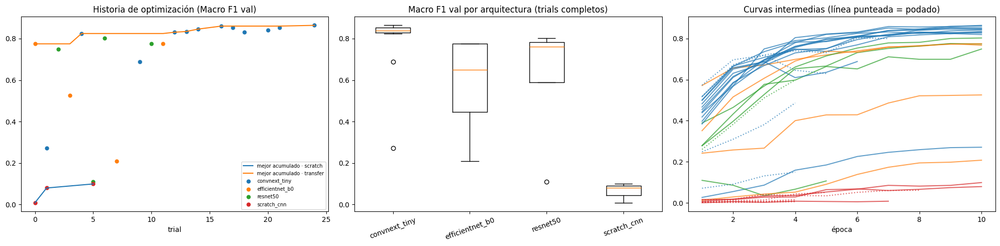

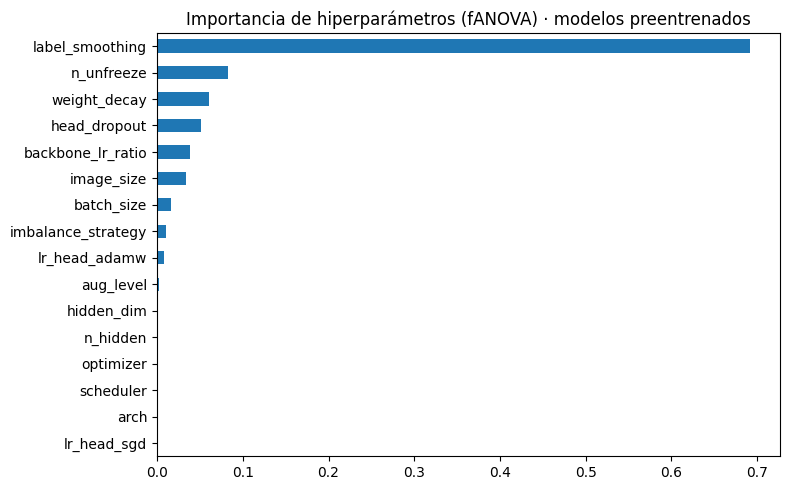

In [26]:
def completed_trials_df(study, label):
    rows = []
    for t in study.trials:
        rows.append({"estudio": label, "trial": t.number, "estado": t.state.name, "macro_f1_val": t.value,
                     "arch": t.params.get("arch", "scratch_cnn"), "minutos": t.user_attrs.get("minutes"),
                     "best_epoch": t.user_attrs.get("best_epoch"), "val_acc": t.user_attrs.get("val_accuracy"),
                     "val_top5": t.user_attrs.get("val_top5_accuracy"), "vram_gb": t.user_attrs.get("peak_vram_gb"),
                     **{f"p_{k}": v for k, v in t.params.items()}})
    return pd.DataFrame(rows)


trials_df = pd.concat([completed_trials_df(study_cnn, "scratch"), completed_trials_df(study_tl, "transfer")],
                      ignore_index=True)
trials_df.to_csv(OUTPUT_DIR / "optuna_todos_los_trials.csv", index=False, encoding="utf-8-sig")
print(trials_df.groupby(["estudio", "estado"]).size().to_string())

done = trials_df[trials_df["estado"] == "COMPLETE"]
if len(done):
    display(done.groupby("arch")["macro_f1_val"].agg(["count", "max", "mean", "std"]).sort_values("max", ascending=False).round(4))
    display(done.sort_values("macro_f1_val", ascending=False).head(10)[
        ["estudio", "trial", "arch", "macro_f1_val", "val_acc", "val_top5", "best_epoch", "minutos", "vram_gb"]].round(4))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
colors = {a: plt.cm.tab10(i) for i, a in enumerate(sorted(trials_df["arch"].unique()))}
for label, st_ in (("scratch", study_cnn), ("transfer", study_tl)):
    vals = [(t.number, t.value) for t in st_.trials if t.state == optuna.trial.TrialState.COMPLETE]
    if vals:
        n, v = zip(*vals)
        axes[0].plot(n, np.maximum.accumulate(v), label=f"mejor acumulado · {label}")
for arch, g in done.groupby("arch"):
    axes[0].scatter(g["trial"], g["macro_f1_val"], color=colors[arch], s=25, label=arch)
axes[0].set_title("Historia de optimización (Macro F1 val)")
axes[0].set_xlabel("trial")
axes[0].legend(fontsize=7)

archs = [a for a in colors if a in set(done["arch"])]
if archs:
    axes[1].boxplot([done.loc[done["arch"] == a, "macro_f1_val"] for a in archs])
    axes[1].set_xticks(range(1, len(archs) + 1))
    axes[1].set_xticklabels(archs, rotation=20)
axes[1].set_title("Macro F1 val por arquitectura (trials completos)")

for t in study_tl.trials + study_cnn.trials:
    if t.intermediate_values:
        steps, vals = zip(*sorted(t.intermediate_values.items()))
        style = "-" if t.state == optuna.trial.TrialState.COMPLETE else ":"
        axes[2].plot(np.array(steps) + 1, vals, style, color=colors.get(t.params.get("arch", "scratch_cnn"), "gray"), alpha=.7)
axes[2].set_title("Curvas intermedias (línea punteada = podado)")
axes[2].set_xlabel("época")
plt.tight_layout()
savefig(fig, "optuna_analisis")
plt.show()

try:
    n_complete_tl = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study_tl.trials)
    if n_complete_tl >= 4:
        imp = optuna.importance.get_param_importances(study_tl)
        fig, ax = plt.subplots(figsize=(8, 5))
        pd.Series(imp).sort_values().plot.barh(ax=ax, color="tab:blue")
        ax.set_title("Importancia de hiperparámetros (fANOVA) · modelos preentrenados")
        plt.tight_layout()
        savefig(fig, "optuna_importancias")
        plt.show()
    else:
        print("ℹ️  Se necesitan al menos 4 trials completos para estimar importancias.")
except Exception as e:
    print(f"ℹ️  No se pudieron calcular importancias: {e}")

In [27]:
def best_of(study):
    complete = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE and "hp" in t.user_attrs]
    return max(complete, key=lambda t: t.value) if complete else None


best_tl, best_cnn = best_of(study_tl), best_of(study_cnn)
candidates = [t for t in (best_tl, best_cnn) if t is not None]
if not candidates:
    print("⚠️  No hay trials completos. Se usará una configuración por defecto conservadora.")
    BEST_HP = {"arch": CANDIDATE_ARCHS[0], "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE, "optimizer": "adamw",
               "scheduler": "cosine", "weight_decay": 1e-2, "aug_level": "medium", "label_smoothing": 0.1,
               "imbalance_strategy": IMBALANCE_STRATEGY, "grad_accum": GRAD_ACCUM_STEPS, "lr_head": 1e-3,
               "lr_backbone": 1e-4, "head_dropout": 0.3, "hidden_dim": 512, "n_hidden": 1, "n_unfreeze": 3}
    BEST_VAL_SEARCH = float("nan")
else:
    winner = max(candidates, key=lambda t: t.value)
    BEST_HP, BEST_VAL_SEARCH = dict(winner.user_attrs["hp"]), winner.value
    if best_tl is not None and best_cnn is not None:
        print(f"Mejor preentrenado: {best_tl.user_attrs['hp']['arch']} → Macro F1 val {best_tl.value:.4f}")
        print(f"Mejor CNN desde cero:               → Macro F1 val {best_cnn.value:.4f}")
        print(f"Diferencia: {best_tl.value - best_cnn.value:+.4f} a favor de "
              f"{'transferencia' if best_tl.value >= best_cnn.value else 'la CNN desde cero'}")

print(f"\n🏆 Configuración seleccionada (Macro F1 val en búsqueda = {BEST_VAL_SEARCH:.4f}):")
print(json.dumps(BEST_HP, indent=2, ensure_ascii=False))
with open(OUTPUT_DIR / "mejores_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump({"hp": BEST_HP, "val_macro_f1_busqueda": BEST_VAL_SEARCH}, f, indent=2, ensure_ascii=False)

Mejor preentrenado: convnext_tiny → Macro F1 val 0.8642
Mejor CNN desde cero:               → Macro F1 val 0.0989
Diferencia: +0.7652 a favor de transferencia

🏆 Configuración seleccionada (Macro F1 val en búsqueda = 0.8642):
{
  "arch": "convnext_tiny",
  "image_size": 256,
  "batch_size": 16,
  "optimizer": "adamw",
  "scheduler": "cosine",
  "weight_decay": 0.002649877529592039,
  "aug_level": "light",
  "label_smoothing": 0.11323958708774307,
  "imbalance_strategy": "class_weights",
  "grad_accum": 1,
  "lr_head": 0.0005175507571404502,
  "lr_backbone": 0.00010764375980499596,
  "head_dropout": 0.23541841226118632,
  "hidden_dim": 512,
  "n_hidden": 1,
  "n_unfreeze": 2
}


## 17. Entrenamiento del mejor modelo

**Qué:** reconstruir el modelo con la configuración ganadora y entrenarlo durante más épocas (`FINAL_EPOCHS`) con early stopping más paciente (`PATIENCE_FINAL`) y una fase 1 algo más larga (`PHASE1_EPOCHS_FINAL`).

**Por qué reentrenar:** durante la búsqueda cada trial tuvo pocas épocas y podía estar podado o truncado; con más épocas el modelo suele mejorar algunos puntos de Macro F1. El checkpoint guardado es el de **mejor Macro F1 de validación**, no el de la última época.

**Alternativa (próximo paso):** reentrenar con train + val usando el número de épocas óptimo encontrado aquí. Gana datos (útil con pocas imágenes por especie) pero pierde la posibilidad de early stopping y de verificar en val.

**Qué esperar:** la fase 1 sube rápido el Macro F1; la fase 2 (fine-tuning) aporta la mayor ganancia en clasificación fina de especies. Si la loss de train sigue bajando mientras la de val sube, hay sobreajuste y el early stopping debe actuar.

In [28]:
hp_hash = hashlib.md5(json.dumps(BEST_HP, sort_keys=True).encode()).hexdigest()[:8]
FINAL_CKPT_DIR = CKPT_DIR / f"final_{RUN_TAG}_{BEST_HP['arch']}_{hp_hash}"
print(f"Entrenando {BEST_HP['arch']} | checkpoints en {FINAL_CKPT_DIR}")
t_start = time.time()
final_res = run_experiment(BEST_HP, FINAL_EPOCHS, PHASE1_EPOCHS_FINAL, PATIENCE_FINAL, max_batches=MAX_BATCHES,
                           ckpt_dir=FINAL_CKPT_DIR, resume=RESUME_FINAL, keep_best=True, verbose=True)
final_model, FINAL_HP, history_df = final_res["model"], final_res["hp"], final_res["history"]
FINAL_IMAGE_SIZE = FINAL_HP["image_size"]
history_df.to_csv(OUTPUT_DIR / "historial_entrenamiento_final.csv", index=False, encoding="utf-8-sig")
print(f"\nTiempo total: {(time.time() - t_start) / 60:.1f} min | mejor Macro F1 val: "
      f"{final_res['best_val_macro_f1']:.4f} en la época {final_res['best_epoch']}")

Entrenando convnext_tiny | checkpoints en c:\Users\User\Desktop\CNN - Aves\outputs_aves76\checkpoints\final_full_convnext_tiny_2e6378c7
Ép  1/30 | fase 1 | bloques 0 | train loss 3.906 acc 0.171 | val loss 2.940 acc 0.388 macroF1 0.3405 top5 0.785 | 31s | VRAM 0.48 GB  ★
Ép  2/30 | fase 1 | bloques 0 | train loss 2.576 acc 0.513 | val loss 2.274 acc 0.596 macroF1 0.5723 top5 0.901 | 6s | VRAM 0.48 GB  ★
Ép  3/30 | fase 1 | bloques 0 | train loss 2.208 acc 0.642 | val loss 2.172 acc 0.665 macroF1 0.6585 top5 0.917 | 6s | VRAM 0.48 GB  ★
Ép  4/30 | fase 2 | bloques 1 | train loss 1.976 acc 0.681 | val loss 1.825 acc 0.706 macroF1 0.6888 top5 0.931 | 8s | VRAM 0.60 GB  ★
Ép  5/30 | fase 2 | bloques 2 | train loss 1.619 acc 0.782 | val loss 1.560 acc 0.799 macroF1 0.7973 top5 0.959 | 11s | VRAM 0.91 GB  ★
Ép  6/30 | fase 2 | bloques 2 | train loss 1.285 acc 0.908 | val loss 1.508 acc 0.822 macroF1 0.8222 top5 0.952 | 10s | VRAM 0.91 GB  ★
Ép  7/30 | fase 2 | bloques 2 | train loss 1.137 ac

✅ Pesos de la mejor época (13) cargados. Macro F1 val = 0.8734


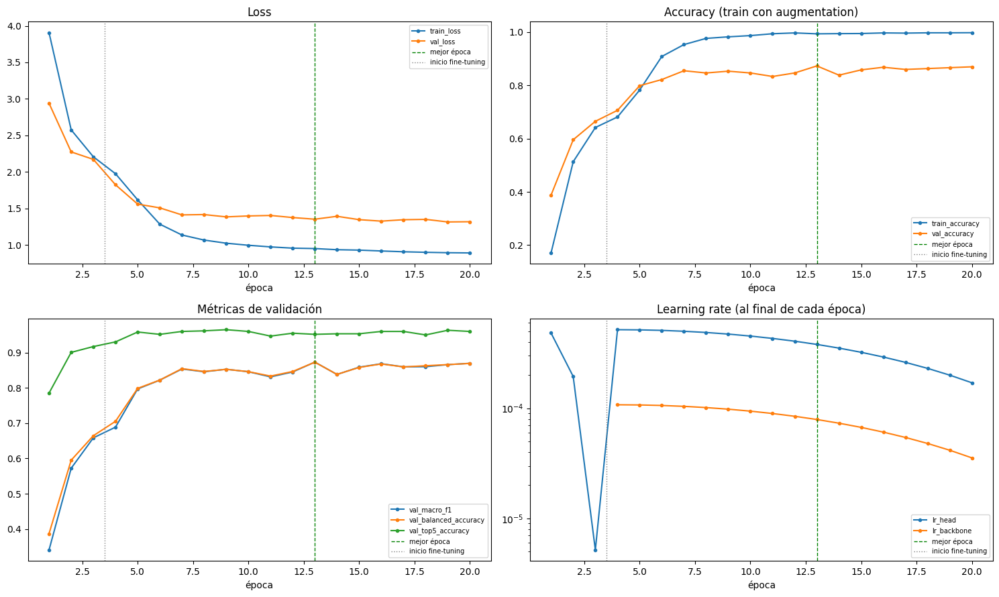

In [29]:
def load_checkpoint_into(model, path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"No existe el checkpoint: {path}")
    try:
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        state = ck["model"] if isinstance(ck, dict) and "model" in ck else ck
        model.load_state_dict(state, strict=True)
        return ck
    except RuntimeError as e:
        raise RuntimeError(
            f"El checkpoint {path.name} no coincide con la arquitectura actual ({e}).\n"
            "→ Verifica que BEST_HP/arquitectura y NUM_CLASSES sean los mismos con los que se guardó.") from e
    except Exception as e:
        raise RuntimeError(f"No se pudo leer el checkpoint {path}: {type(e).__name__}: {e}. "
                           "Puede estar corrupto (ejecución interrumpida al guardar).") from e


best_ckpt = load_checkpoint_into(final_model, FINAL_CKPT_DIR / "best.pth")
print(f"✅ Pesos de la mejor época ({best_ckpt['epoch']}) cargados. Macro F1 val = {best_ckpt['val_macro_f1']:.4f}")

h = history_df
best_ep = int(h.loc[h["val_macro_f1"].idxmax(), "epoch"])
phase2_start = h.loc[h["phase"] == 2, "epoch"].min() if (h["phase"] == 2).any() else None
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
panels = [(axes[0, 0], ["train_loss", "val_loss"], "Loss"),
          (axes[0, 1], ["train_accuracy", "val_accuracy"], "Accuracy (train con augmentation)"),
          (axes[1, 0], ["val_macro_f1", "val_balanced_accuracy", "val_top5_accuracy"], "Métricas de validación")]
for ax, cols, title in panels:
    for c in cols:
        ax.plot(h["epoch"], h[c], marker="o", ms=3, label=c)
    ax.set_title(title)
for c in ("lr_head", "lr_backbone"):
    if h[c].notna().any():
        axes[1, 1].plot(h["epoch"], h[c], marker="o", ms=3, label=c)
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Learning rate (al final de cada época)")
for ax in axes.ravel():
    ax.axvline(best_ep, color="green", ls="--", lw=1, label="mejor época")
    if phase2_start is not None and not pd.isna(phase2_start):
        ax.axvline(phase2_start - 0.5, color="gray", ls=":", lw=1, label="inicio fine-tuning")
    ax.set_xlabel("época")
    ax.legend(fontsize=7)
plt.tight_layout()
savefig(fig, "curvas_entrenamiento_final")
plt.show()

## 18. Evaluación final sobre test

Se muestran juntas las métricas de validación (con el modelo final) y de test: una diferencia grande sugiere que la selección sobreajustó al conjunto de validación o que las particiones tienen distribuciones distintas.

In [30]:
TEST_FLAG = OUTPUT_DIR / f"test_evaluado_{RUN_TAG}.flag"
if TEST_FLAG.exists():
    print(f"⚠️  El conjunto de test ya se evaluó antes ({TEST_FLAG.read_text(encoding='utf-8').strip()}).\n"
          "   Si cambiaste decisiones tras ver test, la métrica deja de ser imparcial.")

eval_criterion = nn.CrossEntropyLoss()
val_loader_final = make_loader(val_df, build_eval_transform(FINAL_IMAGE_SIZE), FINAL_HP["batch_size"] * 2)
val_metrics_final = evaluate(final_model, val_loader_final, eval_criterion)
shutdown_loader(val_loader_final)

test_loader = make_loader(test_df, build_eval_transform(FINAL_IMAGE_SIZE), FINAL_HP["batch_size"] * 2)
test_metrics, y_test, p_test = evaluate(final_model, test_loader, eval_criterion, return_outputs=True)
shutdown_loader(test_loader)
pred_test = p_test.argmax(1)
TEST_FLAG.write_text(f"evaluado el {time.strftime('%Y-%m-%d %H:%M:%S')} con {FINAL_HP['arch']} ({hp_hash})", encoding="utf-8")

metrics_table = pd.DataFrame({"validación": val_metrics_final, "test": test_metrics}).round(4)
display(metrics_table)
with open(OUTPUT_DIR / "metricas_finales.json", "w", encoding="utf-8") as f:
    json.dump({"val": val_metrics_final, "test": test_metrics, "arch": FINAL_HP["arch"], "hp": FINAL_HP,
               "n_test": int(len(y_test))}, f, indent=2, ensure_ascii=False)

,validación,test
accuracy,0.8729,0.8507
balanced_accuracy,0.8731,0.8499
macro_precision,0.8876,0.8620
macro_recall,0.8731,0.8499
macro_f1,0.8734,0.8467
weighted_f1,0.8735,0.8479
top3_accuracy,0.9373,0.9379
top5_accuracy,0.9521,0.9513
loss,0.7265,0.7100


Classification report (test):
                            precision    recall  f1-score   support

        Actitis macularius      1.000     0.750     0.857         8
   Anisognathus somptuosus      0.857     0.857     0.857         7
Anthracothorax nigricollis      1.000     1.000     1.000         8
         Aramides cajaneus      1.000     0.875     0.933         8
               Ardea cocoi      0.778     0.875     0.824         8
            Ardea herodias      0.667     0.750     0.706         8
                Ardea ibis      0.800     1.000     0.889         8
      Arremon atricapillus      0.875     1.000     0.933         7
             Asio flammeus      0.727     1.000     0.842         8
   Boissonneaua flavescens      0.727     1.000     0.842         8
          Buteo brachyurus      0.375     0.375     0.375         8
             Buteo nitidus      1.000     0.375     0.545         8
           Buteo swainsoni      0.667     0.571     0.615         7
        Buthraupi

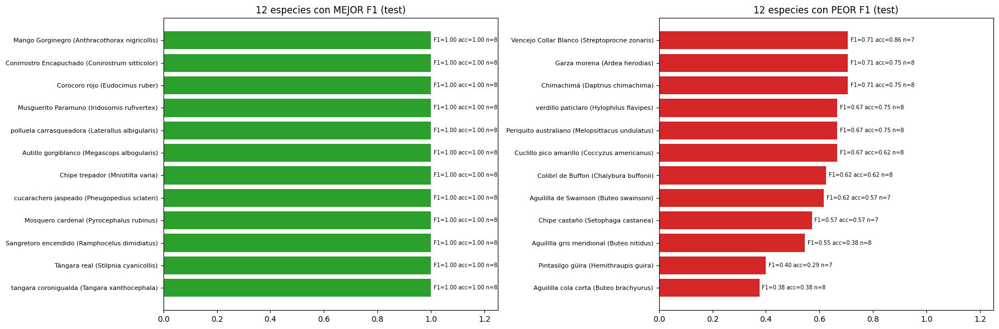

In [31]:
report = classification_report(y_test, pred_test, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES,
                               output_dict=True, zero_division=0)
per_class = pd.DataFrame({
    "especie": CLASS_NAMES,
    "nombre_comun": [sci_to_common[c] for c in CLASS_NAMES],
    "n_test": [int(report[c]["support"]) for c in CLASS_NAMES],
    "aciertos": [int(((y_test == i) & (pred_test == i)).sum()) for i in range(NUM_CLASSES)],
    "precision": [report[c]["precision"] for c in CLASS_NAMES],
    "recall": [report[c]["recall"] for c in CLASS_NAMES],
    "f1": [report[c]["f1-score"] for c in CLASS_NAMES],
})
per_class["accuracy"] = per_class["aciertos"] / per_class["n_test"].replace(0, np.nan)   # accuracy por clase = recall
per_class.to_csv(OUTPUT_DIR / "metricas_por_especie_test.csv", index=False, encoding="utf-8-sig")

print("Classification report (test):")
print(classification_report(y_test, pred_test, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES,
                            zero_division=0, digits=3))

ranked = per_class.sort_values(["f1", "accuracy"], ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, df_, title, color in ((axes[0], ranked.head(12), "12 especies con MEJOR F1 (test)", "tab:green"),
                              (axes[1], ranked.tail(12), "12 especies con PEOR F1 (test)", "tab:red")):
    labels = [f"{r.nombre_comun} ({r.especie})" if r.nombre_comun != r.especie else r.especie for r in df_.itertuples()]
    ax.barh(labels[::-1], df_["f1"].values[::-1], color=color)
    for y_, (f1v, acc, n) in enumerate(zip(df_["f1"].values[::-1], df_["accuracy"].values[::-1], df_["n_test"].values[::-1])):
        ax.text(f1v + 0.01, y_, f"F1={f1v:.2f} acc={acc:.2f} n={n}", va="center", fontsize=7)
    ax.set_xlim(0, 1.25)
    ax.set_title(title)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
savefig(fig, "mejores_peores_especies")
plt.show()

## 19. Comparación con acc_baseline

Se compara la **accuracy por especie** (aciertos / imágenes de test de esa especie) con la columna `acc_baseline` del CSV.

> ⚠️ **Interpretación con cautela.** Con ~8 imágenes de test por especie, cada imagen vale **12.5 puntos porcentuales**. Un cambio de 0.25 a 0.50 puede deberse a dos imágenes. Por eso se añade el **intervalo de confianza de Wilson al 95 %**: si el baseline queda dentro del intervalo, la diferencia no es concluyente para esa especie. Las conclusiones robustas son las agregadas (media de las 76 especies, número de especies que mejoran). Además, si el `n_test` actual difiere del CSV, el test no es exactamente el mismo que el del baseline.

$$\text{Wilson: } \frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}, \quad z = 1.96$$

Accuracy media por especie — modelo: 0.850 | baseline: 0.149 | diferencia media: +0.701
Especies: {'mejora': 76} | diferencias concluyentes (baseline fuera del IC95): 74
ℹ️  11 especies tienen un n_test distinto al del CSV: la comparación no es sobre el mismo test exacto.


,especie,nombre_comun,n_test,acc_baseline,accuracy,diferencia,resultado,ic95_inf,ic95_sup,dif_concluyente
8,Asio flammeus,Búho Sabanero,8,0.12,1.000,0.880,mejora,0.676,1.000,True
9,Boissonneaua flavescens,Colibrí Colihabano,8,0.12,1.000,0.880,mejora,0.676,1.000,True
6,Ardea ibis,Garcilla bueyera occidental,8,0.12,1.000,0.880,mejora,0.676,1.000,True
7,Arremon atricapillus,cerquero cabecinegro,7,0.12,1.000,0.880,mejora,0.646,1.000,True
30,Grallaria alticola,Grallaria alticola,8,0.12,1.000,0.880,mejora,0.676,1.000,True
43,Megarynchus pitangua,Luis pico grueso,8,0.12,1.000,0.880,mejora,0.676,1.000,True
41,Laterallus albigularis,polluela carrasqueadora,8,0.12,1.000,0.880,mejora,0.676,1.000,True
25,Eubucco bourcierii,Torito cabecirrojo,8,0.12,1.000,0.880,mejora,0.676,1.000,True
20,Columbina talpacoti,Tortolita Canela,7,0.12,1.000,0.880,mejora,0.646,1.000,True
21,Conirostrum sitticolor,Conirrostro Encapuchado,8,0.12,1.000,0.880,mejora,0.676,1.000,True


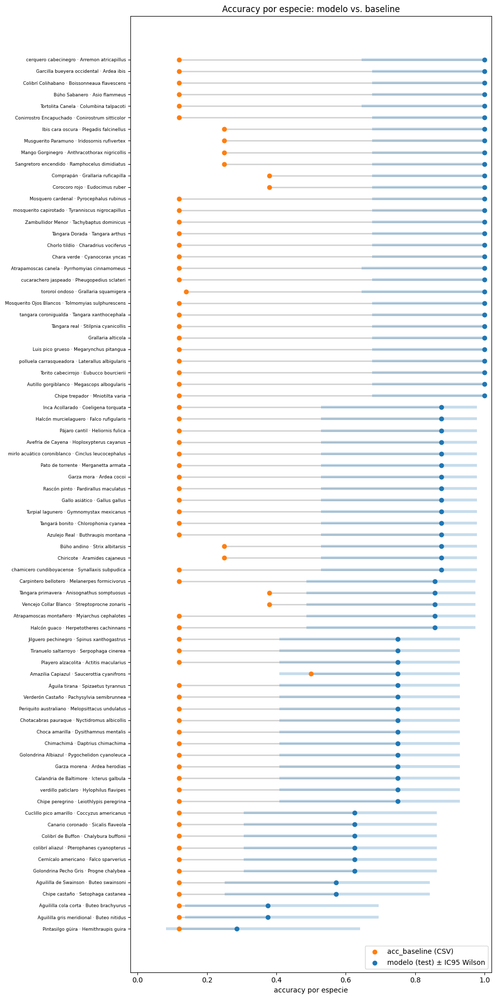

In [32]:
def wilson_ci(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z ** 2 / n
    center = (p + z ** 2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return max(0.0, center - half), min(1.0, center + half)


cmp_df = per_class.merge(species_df[["especie", "acc_baseline", "n_test"]].rename(columns={"n_test": "n_test_csv"}),
                         on="especie", how="left")
cmp_df["diferencia"] = cmp_df["accuracy"] - cmp_df["acc_baseline"]
cmp_df["resultado"] = np.select([cmp_df["diferencia"] > 1e-9, cmp_df["diferencia"] < -1e-9],
                                ["mejora", "disminuye"], default="igual")
ci = [wilson_ci(k, n) for k, n in zip(cmp_df["aciertos"], cmp_df["n_test"])]
cmp_df["ic95_inf"], cmp_df["ic95_sup"] = zip(*ci)
cmp_df["dif_concluyente"] = (cmp_df["acc_baseline"] < cmp_df["ic95_inf"]) | (cmp_df["acc_baseline"] > cmp_df["ic95_sup"])
cmp_df = cmp_df.sort_values("diferencia", ascending=False)
cmp_df.to_csv(OUTPUT_DIR / "comparacion_baseline.csv", index=False, encoding="utf-8-sig")

print(f"Accuracy media por especie — modelo: {cmp_df['accuracy'].mean():.3f} | baseline: {cmp_df['acc_baseline'].mean():.3f} "
      f"| diferencia media: {cmp_df['diferencia'].mean():+.3f}")
print("Especies:", cmp_df["resultado"].value_counts().to_dict(),
      f"| diferencias concluyentes (baseline fuera del IC95): {int(cmp_df['dif_concluyente'].sum())}")
n_mismatch = int((cmp_df["n_test"] != cmp_df["n_test_csv"]).sum())
if n_mismatch:
    print(f"ℹ️  {n_mismatch} especies tienen un n_test distinto al del CSV: la comparación no es sobre el mismo test exacto.")
display(cmp_df[["especie", "nombre_comun", "n_test", "acc_baseline", "accuracy", "diferencia", "resultado",
                "ic95_inf", "ic95_sup", "dif_concluyente"]].round(3))

d = cmp_df.sort_values("accuracy")
fig, ax = plt.subplots(figsize=(10, 20))
yy = np.arange(len(d))
ax.hlines(yy, d["acc_baseline"], d["accuracy"], color="lightgray", lw=2)
ax.errorbar(d["accuracy"], yy, xerr=[d["accuracy"] - d["ic95_inf"], d["ic95_sup"] - d["accuracy"]],
            fmt="none", ecolor="tab:blue", alpha=.25, lw=4)
ax.scatter(d["acc_baseline"], yy, color="tab:orange", label="acc_baseline (CSV)", zorder=3)
ax.scatter(d["accuracy"], yy, color="tab:blue", label="modelo (test) ± IC95 Wilson", zorder=3)
ax.set_yticks(yy)
ax.set_yticklabels([f"{c} · {s}" if c != s else s for c, s in zip(d["nombre_comun"], d["especie"])], fontsize=6.5)
ax.set_xlim(-0.02, 1.02)
ax.set_xlabel("accuracy por especie")
ax.set_title("Accuracy por especie: modelo vs. baseline")
ax.legend(loc="lower right")
plt.tight_layout()
savefig(fig, "comparacion_baseline")
plt.show()

## 20. Matriz de confusión y errores por especie

- **Matriz absoluta:** filas = especie real, columnas = predicha; la diagonal son aciertos.
- **Matriz normalizada por fila:** cada fila suma 1; la diagonal es el recall de cada especie. Más legible cuando las clases tienen distinto número de imágenes.
- **Pares más confundidos:** suelen ser especies del mismo género o con plumaje parecido (p. ej. *Grallaria* spp., *Ardea* spp., *Buteo* spp., *Tangara*/*Stilpnia*). Son candidatos a más datos o a mayor resolución.
- **Ejemplos** con imagen, especie real, predicción, confianza y las cinco clases más probables.

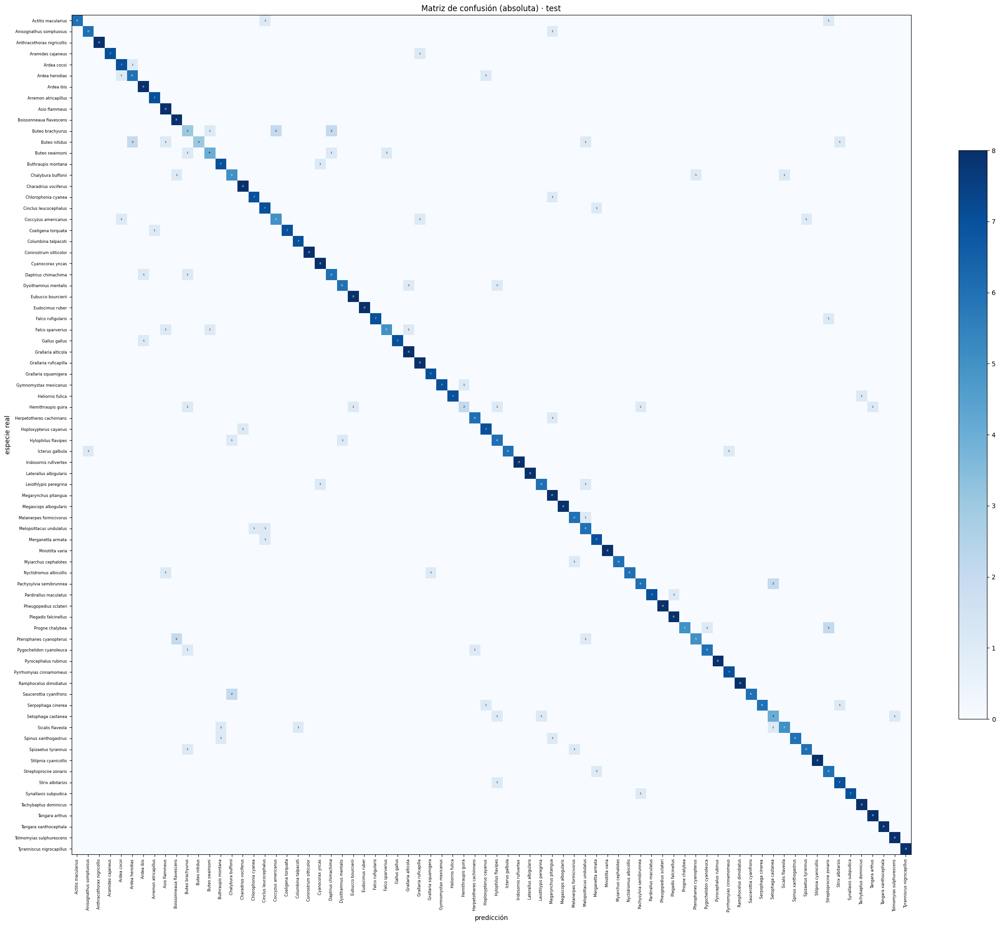

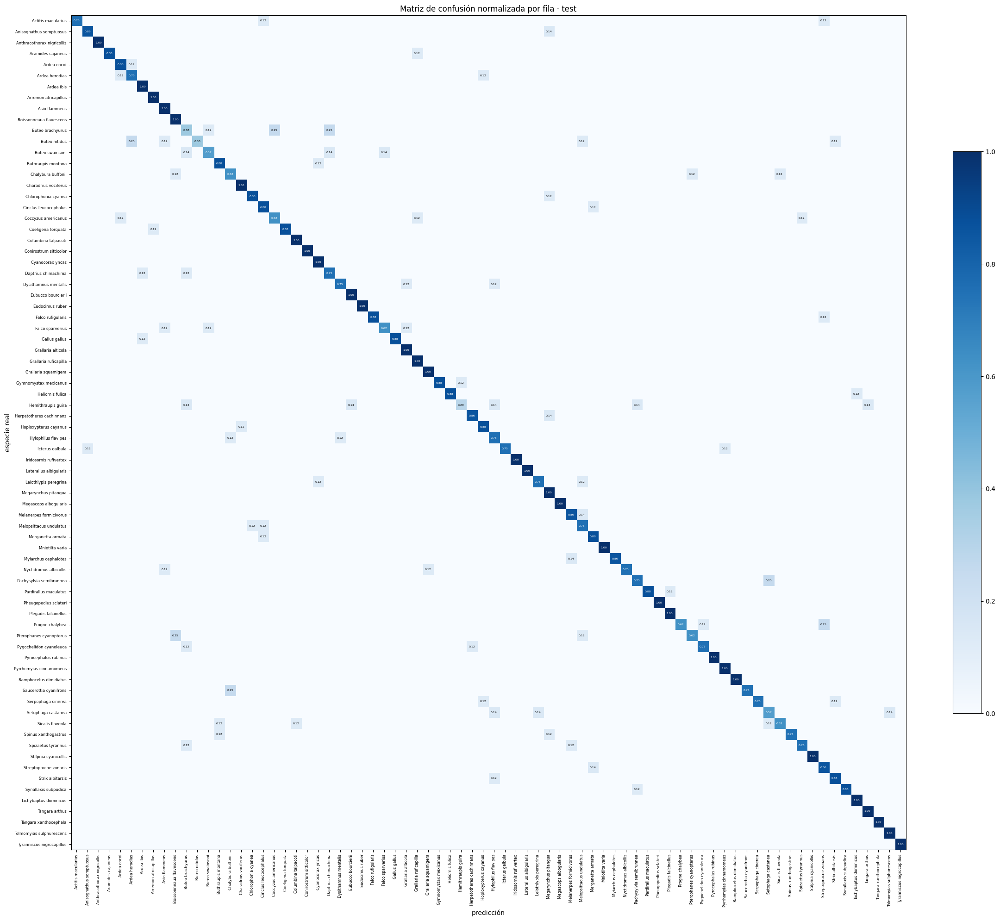

Pares de especies más confundidos (test):


,especie_real,nombre_real,predicha_como,nombre_predicho,veces,% de la clase real
8,Buteo brachyurus,Aguililla cola corta,Coccyzus americanus,Cuclillo pico amarillo,2,25.0
9,Buteo brachyurus,Aguililla cola corta,Daptrius chimachima,Chimachimá,2,25.0
10,Buteo nitidus,Aguililla gris meridional,Ardea herodias,Garza morena,2,25.0
58,Pachysylvia semibrunnea,Verderón Castaño,Setophaga castanea,Chipe castaño,2,25.0
61,Progne chalybea,Golondrina Pecho Gris,Streptoprocne zonaris,Vencejo Collar Blanco,2,25.0
62,Pterophanes cyanopterus,colibrí aliazul,Boissonneaua flavescens,Colibrí Colihabano,2,25.0
66,Saucerottia cyanifrons,Amazilia Capiazul,Chalybura buffonii,Colibrí de Buffon,2,25.0
2,Anisognathus somptuosus,Tángara primavera,Megarynchus pitangua,Luis pico grueso,1,14.3
14,Buteo swainsoni,Aguililla de Swainson,Buteo brachyurus,Aguililla cola corta,1,14.3
15,Buteo swainsoni,Aguililla de Swainson,Daptrius chimachima,Chimachimá,1,14.3


In [33]:
cm = confusion_matrix(y_test, pred_test, labels=list(range(NUM_CLASSES)))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUTPUT_DIR / "matriz_confusion_test.csv", encoding="utf-8-sig")
pd.DataFrame(cm_norm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUTPUT_DIR / "matriz_confusion_test_normalizada.csv", encoding="utf-8-sig")

for mat, title, fname, fmt in ((cm, "Matriz de confusión (absoluta) · test", "matriz_confusion_absoluta", "d"),
                               (cm_norm, "Matriz de confusión normalizada por fila · test", "matriz_confusion_normalizada", ".2f")):
    fig, ax = plt.subplots(figsize=(22, 20))
    im = ax.imshow(mat, cmap="Blues", vmin=0)
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=6)
    ax.set_yticklabels(CLASS_NAMES, fontsize=6)
    ax.set_xlabel("predicción")
    ax.set_ylabel("especie real")
    thresh = mat.max() / 2 if mat.max() > 0 else 1
    for i, j in zip(*np.nonzero(mat)):
        ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center", fontsize=4.5,
                color="white" if mat[i, j] > thresh else "black")
    fig.colorbar(im, fraction=0.03)
    ax.set_title(title)
    plt.tight_layout()
    savefig(fig, fname)
    plt.show()

off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(i, j, off[i, j]) for i, j in zip(*np.nonzero(off))]
confused = pd.DataFrame([{"especie_real": CLASS_NAMES[i], "nombre_real": sci_to_common[CLASS_NAMES[i]],
                          "predicha_como": CLASS_NAMES[j], "nombre_predicho": sci_to_common[CLASS_NAMES[j]],
                          "veces": int(c), "% de la clase real": round(100 * c / max(cm[i].sum(), 1), 1)}
                         for i, j, c in pairs])
if len(confused):
    confused = confused.sort_values(["veces", "% de la clase real"], ascending=False)
    confused.to_csv(OUTPUT_DIR / "pares_mas_confundidos.csv", index=False, encoding="utf-8-sig")
    print("Pares de especies más confundidos (test):")
    display(confused.head(15))

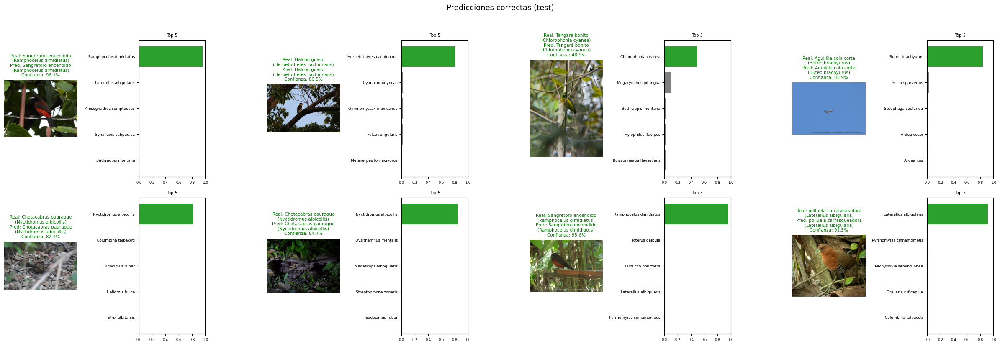

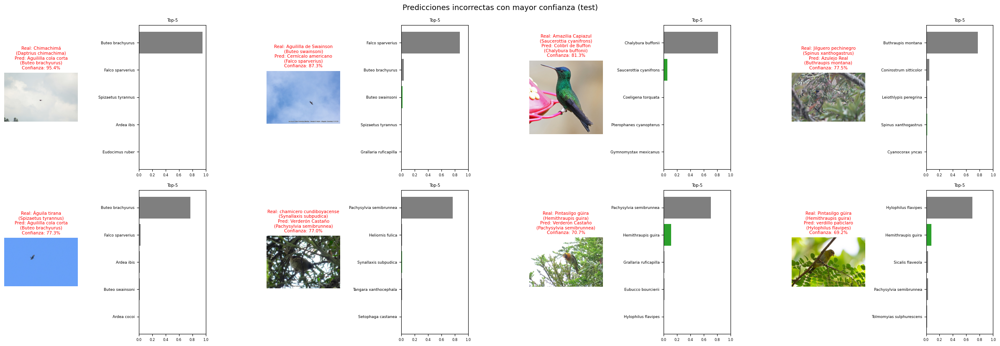

In [34]:
def label_text(idx):
    sp = CLASS_NAMES[idx]
    common = sci_to_common[sp]
    return sp if common == sp else f"{common}\n({sp})"


def show_predictions(indices, title, fname, n_cols=4):
    indices = list(indices)
    if not indices:
        print(f"Sin ejemplos para: {title}")
        return
    n_rows = math.ceil(len(indices) / n_cols)
    fig = plt.figure(figsize=(6 * n_cols, 4.2 * n_rows))
    gs = fig.add_gridspec(n_rows, n_cols * 2, width_ratios=[1.1, 1] * n_cols)
    for k, i in enumerate(indices):
        r, c = divmod(k, n_cols)
        ax_img, ax_bar = fig.add_subplot(gs[r, 2 * c]), fig.add_subplot(gs[r, 2 * c + 1])
        ax_img.imshow(load_rgb(test_df.loc[i, "path"]))
        ok = y_test[i] == pred_test[i]
        ax_img.set_title(f"Real: {label_text(y_test[i])}\nPred: {label_text(pred_test[i])}\nConfianza: {p_test[i].max():.1%}",
                         fontsize=7.5, color="green" if ok else "red")
        ax_img.axis("off")
        top5 = np.argsort(-p_test[i])[:5]
        names = [CLASS_NAMES[t] for t in top5][::-1]
        colors_ = ["tab:green" if t == y_test[i] else "tab:gray" for t in top5][::-1]
        ax_bar.barh(names, p_test[i][top5][::-1], color=colors_)
        ax_bar.set_xlim(0, 1)
        ax_bar.tick_params(axis="y", labelsize=6.5)
        ax_bar.tick_params(axis="x", labelsize=6)
        ax_bar.set_title("Top-5", fontsize=7)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    savefig(fig, fname)
    plt.show()


rng = np.random.default_rng(RANDOM_SEED)
correct_idx = np.where(y_test == pred_test)[0]
wrong_idx = np.where(y_test != pred_test)[0]
show_predictions(rng.choice(correct_idx, size=min(8, len(correct_idx)), replace=False) if len(correct_idx) else [],
                 "Predicciones correctas (test)", "predicciones_correctas")
# Errores más "seguros" primero: los más informativos para entender confusiones sistemáticas
wrong_sorted = wrong_idx[np.argsort(-p_test[wrong_idx].max(1))] if len(wrong_idx) else []
show_predictions(wrong_sorted[:8], "Predicciones incorrectas con mayor confianza (test)", "predicciones_incorrectas")

## 21. Grad-CAM

**Qué es:** Grad-CAM calcula, para la clase predicha, el gradiente de su *logit* respecto a los mapas de activación de la última capa convolucional, promedia ese gradiente por canal para obtener un peso de importancia y combina los mapas ponderados (con ReLU). El resultado, ampliado al tamaño de la imagen, resalta las regiones que **más aumentan la puntuación** de esa clase.

$$L^c_{\text{Grad-CAM}} = \mathrm{ReLU}\Big(\sum_k \alpha_k^c A^k\Big), \qquad \alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}}$$

**Cómo leerlo:** en un buen modelo de aves esperamos calor sobre la cabeza, el pico, el pecho o el patrón de alas. Calor sobre el fondo (agua, cielo, ramas, comederos) sugiere que el modelo usa **atajos de contexto**.

**Limitaciones:**
- Resolución gruesa: el mapa sale de una rejilla de 7×7 u 8×8, por lo que solo localiza zonas aproximadas.
- Muestra correlación con la puntuación, no qué característica *causa* la decisión; dos mapas parecidos pueden ocultar razonamientos distintos.
- Depende de la capa elegida y puede ser poco fiel en arquitecturas como ConvNeXt (LayerNorm, kernels grandes).
- No debe usarse para "validar" un modelo; es una herramienta de diagnóstico para generar hipótesis.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.023725489154458046..1.000000011920929].


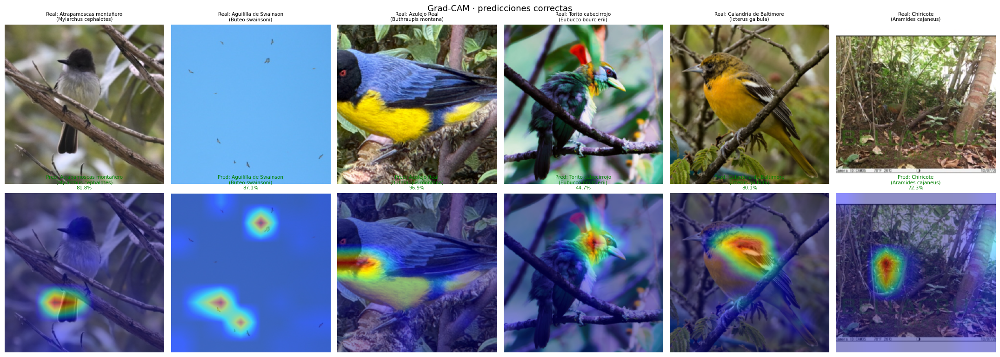

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.02803921513259411..1.000000011920929].


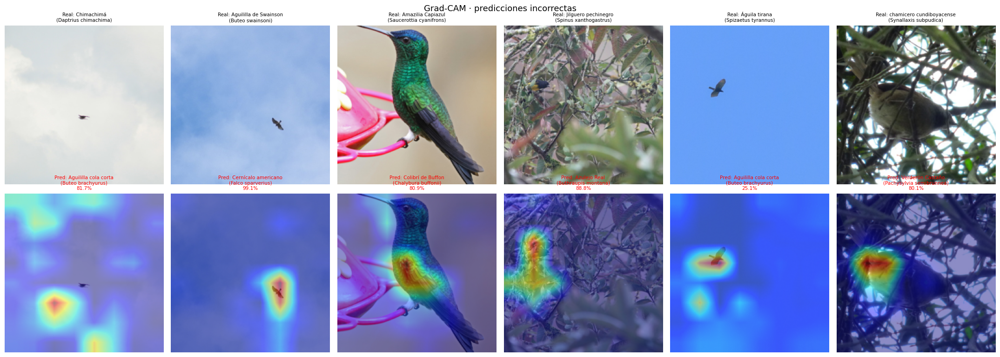

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.03235293924808502..1.000000011920929].


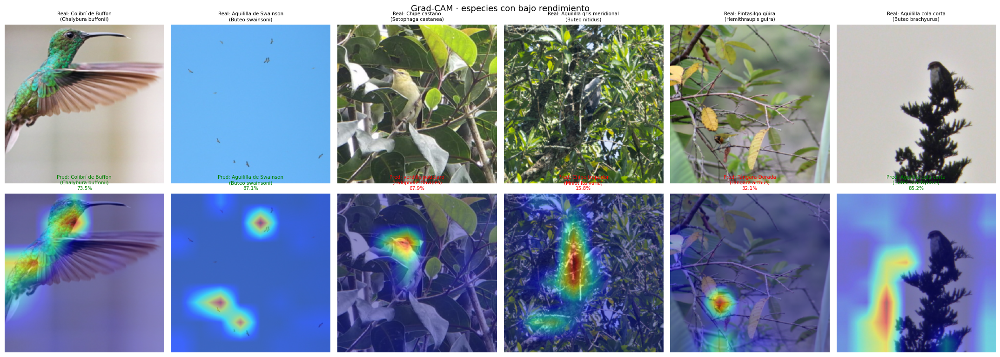

In [35]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = target_layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inp, out):
        self.acts = out
        if out.requires_grad:
            out.register_hook(self._save_grad)

    def _save_grad(self, grad):
        self.grads = grad

    def __call__(self, x, class_idx=None):
        self.model.eval()
        x = x.clone().to(DEVICE).float().requires_grad_(True)   # garantiza gradiente aunque haya capas congeladas
        self.model.zero_grad(set_to_none=True)
        logits = self.model(x).float()
        probs = F.softmax(logits, dim=1)[0].detach().cpu().numpy()
        idx = int(logits.argmax(1)) if class_idx is None else int(class_idx)
        logits[0, idx].backward()
        weights = self.grads.float().mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.acts.float()).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = cam - cam.min()
        cam = (cam / cam.max().clamp(min=1e-8)).detach().cpu().numpy()
        self.model.zero_grad(set_to_none=True)
        return cam, idx, probs

    def remove(self):
        self.handle.remove()


def show_gradcam(indices, title, fname):
    indices = list(indices)
    if not indices:
        print(f"Sin ejemplos para: {title}")
        return
    cam_engine = GradCAM(final_model, final_model.get_gradcam_layer())
    tf = build_eval_transform(FINAL_IMAGE_SIZE)
    fig, axes = plt.subplots(2, len(indices), figsize=(3.6 * len(indices), 7.8))
    axes = np.array(axes).reshape(2, -1)
    try:
        for k, i in enumerate(indices):
            x = tf(load_rgb(test_df.loc[i, "path"])).unsqueeze(0)
            cam, pred_idx, probs = cam_engine(x)
            base = denormalize(x[0])
            heat = plt.cm.jet(cam)[..., :3]
            ok = pred_idx == y_test[i]
            axes[0, k].imshow(base)
            axes[0, k].set_title(f"Real: {label_text(y_test[i])}", fontsize=7.5)
            axes[1, k].imshow(0.55 * base + 0.45 * heat)
            axes[1, k].set_title(f"Pred: {label_text(pred_idx)}\n{probs[pred_idx]:.1%}", fontsize=7.5,
                                 color="green" if ok else "red")
            for a in axes[:, k]:
                a.axis("off")
    finally:
        cam_engine.remove()
        final_model.zero_grad(set_to_none=True)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    savefig(fig, fname)
    plt.show()


show_gradcam(rng.choice(correct_idx, size=min(6, len(correct_idx)), replace=False) if len(correct_idx) else [],
             "Grad-CAM · predicciones correctas", "gradcam_correctas")
show_gradcam(wrong_sorted[:6], "Grad-CAM · predicciones incorrectas", "gradcam_incorrectas")
worst_classes = [class_to_idx[s] for s in ranked.tail(6)["especie"]]
worst_examples = [int(np.where(y_test == c)[0][0]) for c in worst_classes if (y_test == c).any()]
show_gradcam(worst_examples, "Grad-CAM · especies con bajo rendimiento", "gradcam_bajo_rendimiento")

## 22. Inferencia sobre una imagen nueva

`predict_image(ruta)` aplica la misma transformación determinista de validación y devuelve las cinco especies más probables con su nombre científico, nombre común y probabilidad.

**Advertencia de dominio cerrado:** el modelo solo conoce estas especies. Ante un ave que no esté en la lista (o una imagen sin aves) **igualmente** devolverá alguna de ellas. Una confianza máxima baja (p. ej. < 40 %) es una señal útil para tratar la predicción como "no segura". Define `NEW_IMAGE_PATH` con la ruta de tu imagen; si es `None`, se usa una imagen de test como demostración.

Imagen: 100268982_167328239.jpg
  1. verdillo paticlaro               (Hylophilus flavipes         )  67.9%
  2. Chipe castaño                    (Setophaga castanea          )   9.9%
  3. Verderón Castaño                 (Pachysylvia semibrunnea     )   3.7%
  4. Chipe peregrino                  (Leiothlypis peregrina       )   1.2%
  5. Grallaria alticola               (Grallaria alticola          )   1.2%


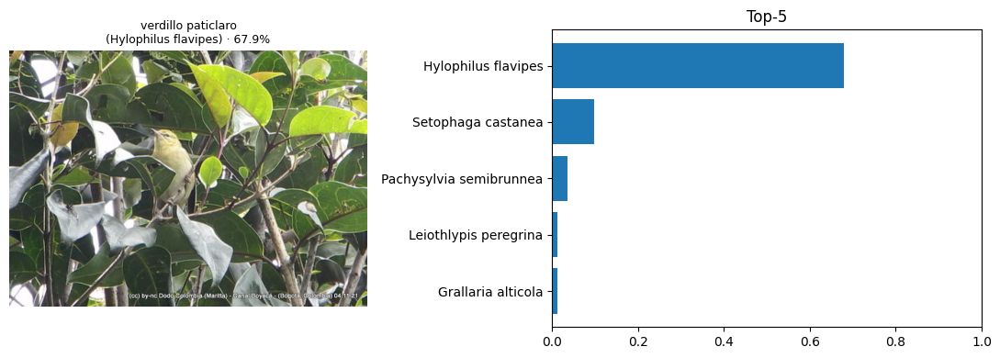

In [36]:
NEW_IMAGE_PATH = None      # ej.: r"C:\Users\User\Pictures\ave.jpg"
LOW_CONFIDENCE = 0.40


@torch.no_grad()
def predict_image(image_path, model=None, image_size=None, top_k=5, show=True):
    model = final_model if model is None else model
    image_size = FINAL_IMAGE_SIZE if image_size is None else image_size
    path = Path(image_path)
    if not path.is_file():
        raise FileNotFoundError(f"No se encontró la imagen: {path}")
    try:
        img = load_rgb(path)
    except Exception as e:
        raise ValueError(f"La imagen no se puede leer (¿corrupta o formato no soportado?): {path} ({e})") from e
    x = build_eval_transform(image_size)(img).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp_enabled()):
        logits = model(x)
    probs = F.softmax(logits.float(), dim=1)[0].cpu()
    top_p, top_i = probs.topk(min(top_k, NUM_CLASSES))
    result = pd.DataFrame({"rank": range(1, len(top_i) + 1),
                           "especie": [CLASS_NAMES[i] for i in top_i.tolist()],
                           "nombre_comun": [sci_to_common[CLASS_NAMES[i]] for i in top_i.tolist()],
                           "probabilidad": top_p.numpy()})
    print(f"Imagen: {path.name}")
    for r in result.itertuples():
        print(f"  {r.rank}. {r.nombre_comun:<32} ({r.especie:<28}) {r.probabilidad:6.1%}")
    if result["probabilidad"].iloc[0] < LOW_CONFIDENCE:
        print(f"⚠️  Confianza baja (< {LOW_CONFIDENCE:.0%}): puede ser una especie fuera de las {NUM_CLASSES} o una imagen difícil.")
    if show:
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.2]})
        a1.imshow(img)
        a1.axis("off")
        a1.set_title(f"{result['nombre_comun'].iloc[0]}\n({result['especie'].iloc[0]}) · {result['probabilidad'].iloc[0]:.1%}", fontsize=9)
        a2.barh(result["especie"][::-1], result["probabilidad"][::-1], color="tab:blue")
        a2.set_xlim(0, 1)
        a2.set_title("Top-5")
        plt.tight_layout()
        plt.show()
    return result


demo_path = NEW_IMAGE_PATH or test_df.sample(1, random_state=RANDOM_SEED)["path"].iloc[0]
_ = predict_image(demo_path)

## 23. Exportación del modelo


| Archivo | Contenido |
|---|---|
| `modelo_aves76.pth` | `state_dict` del mejor modelo |
| `modelo_aves76_bundle.pth` | Pesos + hiperparámetros + clases + normalización + versiones (todo en uno) |
| `model_config.json` | Arquitectura, hiperparámetros, tamaño de entrada, media/desviación |
| `class_to_idx.json`, `especies_nombres.csv` | Mapeos índice ↔ nombre científico ↔ nombre común |
| `metricas_finales.json`, `metricas_por_especie_test.csv`, `comparacion_baseline.csv` | Métricas |
| `historial_entrenamiento_final.csv`, `optuna_todos_los_trials.csv`, `optuna_aves76.db` | Historial y estudio de Optuna |
| `matriz_confusion_*.csv`, `figuras/*.png` | Matriz de confusión y gráficos |
| `modelo_aves76_torchscript.pt` *(opcional)* | Modelo autocontenido para C++/Python sin el código de la clase |
| `modelo_aves76.onnx` *(opcional)* | Formato abierto para ONNX Runtime, TensorRT, OpenVINO, etc. |

`load_exported_model()` reconstruye el modelo desde la carpeta exportada sin volver a descargar pesos de ImageNet.

In [37]:
EXPORT_TORCHSCRIPT = True
EXPORT_ONNX = True

final_model.eval()
state_cpu = {k: v.detach().cpu() for k, v in final_model.state_dict().items()}
torch.save(state_cpu, EXPORT_DIR / "modelo_aves76.pth")
model_config = {"arch": FINAL_HP["arch"], "hp": FINAL_HP, "num_classes": NUM_CLASSES, "image_size": FINAL_IMAGE_SIZE,
                "eval_resize_ratio": 1.14, "mean": list(IMAGENET_MEAN), "std": list(IMAGENET_STD),
                "best_epoch": int(final_res["best_epoch"]), "val_macro_f1": float(final_res["best_val_macro_f1"]),
                "test_macro_f1": float(test_metrics["macro_f1"]), "quick_mode": QUICK_MODE}
torch.save({"state_dict": state_cpu, "config": model_config, "class_to_idx": class_to_idx,
            "sci_to_common": sci_to_common, "versions": VERSIONS}, EXPORT_DIR / "modelo_aves76_bundle.pth")
with open(EXPORT_DIR / "model_config.json", "w", encoding="utf-8") as f:
    json.dump(model_config, f, indent=2, ensure_ascii=False)
with open(EXPORT_DIR / "class_to_idx.json", "w", encoding="utf-8") as f:
    json.dump(class_to_idx, f, indent=2, ensure_ascii=False)
pd.DataFrame({"idx": range(NUM_CLASSES), "especie": CLASS_NAMES,
              "nombre_comun": [sci_to_common[c] for c in CLASS_NAMES],
              "nombre_comun_vacio_en_csv": [sp_info.loc[c, "nombre_comun"] == "" for c in CLASS_NAMES],
              "display_name": DISPLAY_NAMES}).to_csv(EXPORT_DIR / "especies_nombres.csv", index=False, encoding="utf-8-sig")

for fname in ("metricas_finales.json", "metricas_por_especie_test.csv", "comparacion_baseline.csv",
              "historial_entrenamiento_final.csv", "optuna_todos_los_trials.csv", "matriz_confusion_test.csv",
              "matriz_confusion_test_normalizada.csv", "pares_mas_confundidos.csv", "mejores_hiperparametros.json",
              f"config_{RUN_TAG}.json", "reporte_emparejamiento.csv", "conteo_imagenes_por_especie.csv"):
    src = OUTPUT_DIR / fname
    if src.exists():
        shutil.copy2(src, EXPORT_DIR / fname)
try:
    shutil.copy2(OUTPUT_DIR / "optuna_aves76.db", EXPORT_DIR / "optuna_aves76.db")
except Exception as e:
    print(f"ℹ️  No se pudo copiar la base de Optuna (puede estar en uso): {e}")
if FIG_DIR.exists():
    shutil.copytree(FIG_DIR, EXPORT_DIR / "figuras", dirs_exist_ok=True)

# ---------- TorchScript y ONNX (en CPU, FP32, formato de memoria estándar) ----------
cpu_model = copy.deepcopy(final_model).float().cpu().to(memory_format=torch.contiguous_format).eval()
example = torch.randn(1, 3, FINAL_IMAGE_SIZE, FINAL_IMAGE_SIZE)
with torch.no_grad():
    ref_out = cpu_model(example)

if EXPORT_TORCHSCRIPT:
    try:
        with torch.no_grad():
            ts = torch.jit.trace(cpu_model, example)
        ts_path = EXPORT_DIR / "modelo_aves76_torchscript.pt"
        ts.save(str(ts_path))
        diff = (torch.jit.load(str(ts_path))(example) - ref_out).abs().max().item()
        print(f"✅ TorchScript guardado ({ts_path.name}) | diferencia máx. vs PyTorch: {diff:.2e}")
    except Exception as e:
        print(f"⚠️  Exportación TorchScript falló: {type(e).__name__}: {e}")

if EXPORT_ONNX:
    onnx_path = EXPORT_DIR / "modelo_aves76.onnx"
    try:
        export_kwargs = dict(input_names=["input"], output_names=["logits"], opset_version=17,
                             dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}})
        try:
            torch.onnx.export(cpu_model, example, str(onnx_path), dynamo=False, **export_kwargs)
        except TypeError:                                   # versiones sin el argumento 'dynamo'
            torch.onnx.export(cpu_model, example, str(onnx_path), **export_kwargs)
        print(f"✅ ONNX guardado ({onnx_path.name})")
        try:
            import onnxruntime as ort
            sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
            onnx_out = sess.run(None, {"input": example.numpy()})[0]
            print(f"   Verificación ONNX Runtime | diferencia máx.: {np.abs(onnx_out - ref_out.numpy()).max():.2e}")
        except ImportError:
            print("   (onnxruntime no instalado: se omite la verificación)")
    except Exception as e:
        print(f"⚠️  Exportación ONNX falló (¿falta 'pip install onnx'?): {type(e).__name__}: {e}")
del cpu_model


def load_exported_model(export_dir=EXPORT_DIR, device=DEVICE):
    """Reconstruye el modelo exportado sin descargar pesos de ImageNet."""
    export_dir = Path(export_dir)
    bundle_path = export_dir / "modelo_aves76_bundle.pth"
    if not bundle_path.exists():
        raise FileNotFoundError(f"No se encontró {bundle_path}")
    try:
        bundle = torch.load(bundle_path, map_location="cpu", weights_only=False)
        model = build_model_from_hp(bundle["config"]["hp"], pretrained=False)
        model.load_state_dict(bundle["state_dict"])
    except Exception as e:
        raise RuntimeError(f"No se pudo cargar el modelo exportado: {type(e).__name__}: {e}") from e
    return model.to(device).eval(), bundle


reloaded_model, reloaded_bundle = load_exported_model()
with torch.no_grad():
    x_chk = build_eval_transform(FINAL_IMAGE_SIZE)(load_rgb(demo_path)).unsqueeze(0).to(DEVICE)
    same = torch.allclose(reloaded_model(x_chk).float(), final_model.eval()(x_chk).float(), atol=1e-3)
print(f"Recarga del modelo exportado: {'✅ coincide' if same else '⚠️ difiere'} | archivos en {EXPORT_DIR}")
del reloaded_model
free_memory()
sorted(p.name for p in EXPORT_DIR.iterdir())

✅ TorchScript guardado (modelo_aves76_torchscript.pt) | diferencia máx. vs PyTorch: 0.00e+00
⚠️  Exportación ONNX falló (¿falta 'pip install onnx'?): OnnxExporterError: Module onnx is not installed!
Recarga del modelo exportado: ✅ coincide | archivos en c:\Users\User\Desktop\CNN - Aves\outputs_aves76\modelo_exportado


['class_to_idx.json',
 'comparacion_baseline.csv',
 'config_full.json',
 'config_quick.json',
 'conteo_imagenes_por_especie.csv',
 'especies_nombres.csv',
 'figuras',
 'historial_entrenamiento_final.csv',
 'matriz_confusion_test.csv',
 'matriz_confusion_test_normalizada.csv',
 'mejores_hiperparametros.json',
 'metricas_finales.json',
 'metricas_por_especie_test.csv',
 'model_config.json',
 'modelo_aves76.pth',
 'modelo_aves76_bundle.pth',
 'modelo_aves76_torchscript.pt',
 'optuna_aves76.db',
 'optuna_todos_los_trials.csv',
 'pares_mas_confundidos.csv',
 'reporte_emparejamiento.csv']

## 24. Conclusiones y limitaciones

In [38]:
best_cnn_val = best_cnn.value if best_cnn is not None else float("nan")
best_tl_val = best_tl.value if best_tl is not None else float("nan")
print("=" * 90)
print(f"RESUMEN DEL EXPERIMENTO ({RUN_TAG.upper()})")
print("=" * 90)
print(f"Clases: {NUM_CLASSES} | imágenes train/val/test: {len(train_df)}/{len(val_df)}/{len(test_df)}")
print(f"Mejor CNN desde cero (val, búsqueda):     Macro F1 = {best_cnn_val:.4f}")
print(f"Mejor modelo preentrenado (val, búsqueda): Macro F1 = {best_tl_val:.4f}")
print(f"Modelo final: {FINAL_HP['arch']} | {FINAL_IMAGE_SIZE}px | mejor época {final_res['best_epoch']}")
for k in ("macro_f1", "accuracy", "balanced_accuracy", "top3_accuracy", "top5_accuracy"):
    print(f"  {k:<18} val = {val_metrics_final[k]:.4f} | test = {test_metrics[k]:.4f}")
print(f"Accuracy media por especie vs baseline: {cmp_df['accuracy'].mean():.3f} vs {cmp_df['acc_baseline'].mean():.3f} "
      f"({cmp_df['diferencia'].mean():+.3f}); mejoran {int((cmp_df['resultado'] == 'mejora').sum())} de {NUM_CLASSES} especies")
if len(confused):
    top_pair = confused.iloc[0]
    print(f"Confusión más frecuente: {top_pair['especie_real']} → {top_pair['predicha_como']} ({top_pair['veces']} veces)")
if QUICK_MODE:
    print("\n⚠️  QUICK_MODE=True: estos números solo validan que el pipeline funciona; NO son resultados reales.")

RESUMEN DEL EXPERIMENTO (FULL)
Clases: 76 | imágenes train/val/test: 2584/606/596
Mejor CNN desde cero (val, búsqueda):     Macro F1 = 0.0989
Mejor modelo preentrenado (val, búsqueda): Macro F1 = 0.8642
Modelo final: convnext_tiny | 256px | mejor época 13
  macro_f1           val = 0.8734 | test = 0.8467
  accuracy           val = 0.8729 | test = 0.8507
  balanced_accuracy  val = 0.8731 | test = 0.8499
  top3_accuracy      val = 0.9373 | test = 0.9379
  top5_accuracy      val = 0.9521 | test = 0.9513
Accuracy media por especie vs baseline: 0.850 vs 0.149 (+0.701); mejoran 76 de 76 especies
Confusión más frecuente: Buteo brachyurus → Coccyzus americanus (2 veces)


### Limitaciones
1. **Test pequeño por clase** (~8 imágenes): métricas por especie muy variables.
2. **Imágenes de ciencia ciudadana**: aves lejanas, desenfocadas, parcialmente ocultas, juveniles/hembras con plumajes distintos, posibles errores de etiqueta.
3. **Posible correlación entre particiones** aunque no haya duplicados: mismas observaciones, mismo observador o misma localidad pueden repartirse entre train y test e inflar ligeramente las métricas.
4. **Selección por validación**: el Macro F1 del mejor trial es optimista; la cifra imparcial es la de test.
5. **Dominio cerrado**: el modelo siempre elige una de las especies, incluso ante aves no incluidas.
6. **Grad-CAM** es orientativo, no explicación causal.
7. **Presupuesto de búsqueda**: 20–30 trials de ~10 épocas exploran parcialmente el espacio; otras configuraciones podrían ser mejores.